# Analysis of Crime Data in Los Angeles, 2020–2023

## Project Objective

The objective of the project is to conduct an analysis of crime data in Los Angeles from a management perspective. The analysis focuses on identifying the areas responsible for the largest share of reported crimes, changes over time, the proportion of crimes involving weapons, the most common types of crimes, and a simple forecast.

### Key Business Questions

1. Which areas of Los Angeles account for approximately 80% of all reported crimes?
2. Which of these areas show an increase, decrease, or stabilization in crime rates between 2020 and 2023?
3. Which 5 types of crimes dominate in each area?
4. Which types of crimes recur across multiple priority areas?
5. What is the proportion of crimes involving weapons, and does it vary across areas?
6. What might the crime rate look like next year for the selected areas?

**Important limitation:** The number of reported crimes is not the same as the “level of danger.” Without data on population, the number of people in a given area, or risk exposure, the number of incidents alone should not be interpreted as an indicator of risk.

### Data Source: Crime Data from 2020 to 2024
Published by data.lacity.org\
City of Los Angeles\
Catalog Last Checked: March 07, 2026 at 08:07 PM\
Dataset Last Updated: March 04, 2026\
_https://catalog.data.gov/dataset/crime-data-from-2020-to-present?from_hint=eyJxIjoiIiwic29ydCI6InBvcHVsYXJpdHkiLCJzcGF0aWFsX2ZpbHRlciI6IiJ9_

Dataset reflects incidents of crime in Los Angeles dating back to 2020. This data is transcribed from original crime reports that are typed on paper and therefore there may be some inaccuracies within the data. Address fields are only provided to the nearest hundred block in order to maintain privacy. This data is as accurate as the data in the database. On March 7th, 2024, the Los Angeles Police Department (LAPD) adopted a new Records Management System for reporting crimes and arrests. As part of this transition, the legacy system is no longer active, and no new information will be entered. Consequently, the Crime Data from 2020 to Present (2024) dataset will no longer be updated. It will remain available on the portal for historical reference only.

# Part One: Loading and Exploring Data

The goal of this part of the project is to familiarize with the data, check for null values and duplicates, and examine the data structure.

In [1]:
### Importing Libraries
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

from scipy import stats
from sklearn.linear_model import LinearRegression
from pathlib import Path

In [2]:
pd.set_option('display.max_columns', None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

In [3]:
### Loading data from a CSV file
csv_file = Path('Crime_Data_from_2020_to_2024.csv')
df = pd.read_csv(csv_file)

In [4]:
### Basic information about dataset
print(f'Number of records: {len(df):,}')
print(f'Number of columns: {df.shape[1]}')

Number of records: 1,004,894
Number of columns: 28


In [5]:
### Displaying random 20 values
df.sample(20)

,DR_NO,Date Rptd,DATE OCC,TIME OCC,AREA,AREA NAME,Rpt Dist No,Part 1-2,Crm Cd,Crm Cd Desc,Mocodes,Vict Age,Vict Sex,Vict Descent,Premis Cd,Premis Desc,Weapon Used Cd,Weapon Desc,Status,Status Desc,Crm Cd 1,Crm Cd 2,Crm Cd 3,Crm Cd 4,LOCATION,Cross Street,LAT,LON
997602,240104354,01/05/2024 12:00:00 AM,01/05/2024 12:00:00 AM,1600,1,Central,132,2,888,TRESPASSING,0910,0,X,X,135.00,MTA PROPERTY OR PARKING LOT,NaN,NaN,IC,Invest Cont,888.00,NaN,NaN,NaN,200 S HOPE ST,NaN,34.05,-118.25
402346,220605255,01/30/2022 12:00:00 AM,11/09/2021 12:00:00 AM,2150,6,Hollywood,649,2,626,INTIMATE PARTNER - SIMPLE ASSAULT,2000 0400 0444 0429,34,M,W,101.00,STREET,400.00,"STRONG-ARM (HANDS, FIST, FEET OR BODILY FORCE)",IC,Invest Cont,626.00,NaN,NaN,NaN,HOLLYWOOD,SERRANO,34.10,-118.31
882764,240308155,03/23/2024 12:00:00 AM,03/22/2024 12:00:00 AM,1800,3,Southwest,328,1,522,"VEHICLE, STOLEN - OTHER (MOTORIZED SCOOTERS, B...",NaN,0,NaN,NaN,101.00,STREET,NaN,NaN,IC,Invest Cont,522.00,NaN,NaN,NaN,2600 PORTLAND ST,NaN,34.03,-118.28
880859,241907008,03/21/2024 12:00:00 AM,03/20/2024 12:00:00 AM,2000,19,Mission,1944,1,510,VEHICLE - STOLEN,NaN,0,NaN,NaN,101.00,STREET,NaN,NaN,IC,Invest Cont,510.00,NaN,NaN,NaN,12100 TRUMAN ST,NaN,34.28,-118.44
493906,220213585,07/19/2022 12:00:00 AM,07/19/2022 12:00:00 AM,1100,2,Rampart,235,1,310,BURGLARY,0344 1601,34,M,B,502.00,"MULTI-UNIT DWELLING (APARTMENT, DUPLEX, ETC)",NaN,NaN,IC,Invest Cont,310.00,NaN,NaN,NaN,2300 BEVERLY BL,NaN,34.07,-118.27
693472,230510396,06/26/2023 12:00:00 AM,06/26/2023 12:00:00 AM,1930,5,Harbor,557,1,350,"THEFT, PERSON",0346 2051 2049,28,M,O,802.00,MUNICIPAL BUS LINE INCLUDES LADOT/DASH,400.00,"STRONG-ARM (HANDS, FIST, FEET OR BODILY FORCE)",IC,Invest Cont,350.00,NaN,NaN,NaN,1ST,GAFFEY,33.74,-118.29
791803,231420208,11/13/2023 12:00:00 AM,11/13/2023 12:00:00 AM,1510,14,Pacific,1415,1,210,ROBBERY,0443 0325 0432 0945 1822,0,X,X,405.00,CLOTHING STORE,511.00,VERBAL THREAT,IC,Invest Cont,210.00,NaN,NaN,NaN,1400 LINCOLN BL,NaN,34.00,-118.46
525031,220613080,07/12/2022 12:00:00 AM,07/12/2022 12:00:00 AM,30,6,Hollywood,643,1,510,VEHICLE - STOLEN,NaN,0,NaN,NaN,101.00,STREET,NaN,NaN,IC,Invest Cont,510.00,NaN,NaN,NaN,1700 N LA BREA AV,NaN,34.10,-118.35
83598,201709059,05/13/2020 12:00:00 AM,05/13/2020 12:00:00 AM,100,17,Devonshire,1737,1,330,BURGLARY FROM VEHICLE,0344 0321 1609,51,F,H,502.00,"MULTI-UNIT DWELLING (APARTMENT, DUPLEX, ETC)",NaN,NaN,IC,Invest Cont,330.00,NaN,NaN,NaN,16800 SAN FERNANDO MISSION BL,NaN,34.27,-118.50
568717,221110801,06/21/2022 12:00:00 AM,06/19/2022 12:00:00 AM,2345,11,Northeast,1117,1,440,THEFT PLAIN - PETTY ($950 & UNDER),1822 0344 0329 0209,38,M,O,501.00,SINGLE FAMILY DWELLING,NaN,NaN,IC,Invest Cont,440.00,NaN,NaN,NaN,4400 CORLISS ST,NaN,34.13,-118.22


In [6]:
### Displaying basic information before formatting
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1004894 entries, 0 to 1004893
Data columns (total 28 columns):
 #   Column          Non-Null Count    Dtype  
---  ------          --------------    -----  
 0   DR_NO           1004894 non-null  int64  
 1   Date Rptd       1004894 non-null  str    
 2   DATE OCC        1004894 non-null  str    
 3   TIME OCC        1004894 non-null  int64  
 4   AREA            1004894 non-null  int64  
 5   AREA NAME       1004894 non-null  str    
 6   Rpt Dist No     1004894 non-null  int64  
 7   Part 1-2        1004894 non-null  int64  
 8   Crm Cd          1004894 non-null  int64  
 9   Crm Cd Desc     1004894 non-null  str    
 10  Mocodes         853296 non-null   str    
 11  Vict Age        1004894 non-null  int64  
 12  Vict Sex        860263 non-null   str    
 13  Vict Descent    860251 non-null   str    
 14  Premis Cd       1004878 non-null  float64
 15  Premis Desc     1004306 non-null  str    
 16  Weapon Used Cd  327216 non-null   float64
 17  

In [7]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
DR_NO,"1,004,894.00",NaN,NaN,NaN,"220,219,030.21","13,190,699.76",817.00,"210,616,831.25","220,915,818.50","231,110,214.75","252,104,036.00"
Date Rptd,1004894,1870,02/02/2023 12:00:00 AM,929,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DATE OCC,1004894,1826,01/01/2020 12:00:00 AM,1164,NaN,NaN,NaN,NaN,NaN,NaN,NaN
TIME OCC,"1,004,894.00",NaN,NaN,NaN,"1,339.90",651.08,1.00,900.00,"1,420.00","1,900.00","2,359.00"
AREA,"1,004,894.00",NaN,NaN,NaN,10.69,6.11,1.00,5.00,11.00,16.00,21.00
AREA NAME,1004894,21,Central,69668,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rpt Dist No,"1,004,894.00",NaN,NaN,NaN,"1,115.61",611.16,101.00,587.00,"1,139.00","1,613.00","2,199.00"
Part 1-2,"1,004,894.00",NaN,NaN,NaN,1.40,0.49,1.00,1.00,1.00,2.00,2.00
Crm Cd,"1,004,894.00",NaN,NaN,NaN,500.14,205.26,110.00,331.00,442.00,626.00,956.00
Crm Cd Desc,1004894,140,VEHICLE - STOLEN,115184,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
### Missing data and duplicates
missing = (df.isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame('missing_count')
    )

missing['missing_pct'] = missing['missing_count'] / len(df) * 100
missing.head(15)

,missing_count,missing_pct
Crm Cd 4,1004830,99.99
Crm Cd 3,1002580,99.77
Crm Cd 2,935740,93.12
Cross Street,850666,84.65
Weapon Used Cd,677678,67.44
Weapon Desc,677678,67.44
Mocodes,151598,15.09
Vict Descent,144643,14.39
Vict Sex,144631,14.39
Premis Desc,588,0.06


In [9]:
print('Number of duplicates:', df.duplicated().sum())

Number of duplicates: 0


No duplicate records were found in the dataset.
The highest rates of missing data are found in the columns `Crm Cd 4` (99.99%), `Crm Cd 3` (99.77%), and `Crm Cd 2` (93.12%) - these are additional crime codes.
`Cross Street` has 84.65% missing values, and `Weapon Used Cd` / `Weapon Desc` has approximately 67.44%. Missing values in the weapon data will be significant when analyzing “with weapon vs. without weapon.”
`Mocodes` (15.09%), `Vict Descent` (14.39%), and `Vict Sex` (14.39%) also contain some missing data.
Key variables for further analysis, such as `Crm Cd`, `Vict Age`, and `Status`, have practically no missing values.

**Conclusion:** The data contains no duplicates, but some columns have a very high number of empty values. In further analysis, it is necessary to focus on variables with good completeness and to appropriately address the missing data regarding weapons.

# Part Two: Data Cleaning and Preparation

In this section, I will process and organize the data so that it can be analyzed and provide more information. 

In [10]:
def checking_pairs_df(df, col1, col2):
    """
    A function to copy the original df, leaving the pair of columns (id and description) needed for analysis. 
    Basic transformations: duplicate removal, sorting, reseting index and displaying data information.
    """
    df_copy = df.copy()

    df_copy = (df_copy[[col1, col2]]
        .drop_duplicates()
        .sort_values(by=col1)
        .reset_index(drop=True)
        )
    
    df_copy.info()

    return df_copy

In [11]:
### Dictionary with key-value pair and the name of the new df where the new data is to be saved

column_pairs = {
    ('AREA', 'AREA NAME'): 'area_df',
    ('Crm Cd', 'Crm Cd Desc'): 'crime_df',
    ('Premis Cd', 'Premis Desc'): 'premis_df',
    ('Weapon Used Cd', 'Weapon Desc'): 'weapon_df',
    ('Status', 'Status Desc'): 'status_df'
}

In [12]:
### Displaying information for each key-value pair

dfs = {}

for (col1, col2), df_name in column_pairs.items():
    print(' ')
    print('##########################################################')
    dfs[df_name] = checking_pairs_df(df=df, col1=col1, col2=col2)

 
##########################################################
<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   AREA       21 non-null     int64
 1   AREA NAME  21 non-null     str  
dtypes: int64(1), str(1)
memory usage: 468.0 bytes
 
##########################################################
<class 'pandas.DataFrame'>
RangeIndex: 140 entries, 0 to 139
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Crm Cd       140 non-null    int64
 1   Crm Cd Desc  140 non-null    str  
dtypes: int64(1), str(1)
memory usage: 2.3 KB
 
##########################################################
<class 'pandas.DataFrame'>
RangeIndex: 315 entries, 0 to 314
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Premis Cd    314 non-null    float64
 1   

In [13]:
### Displaying new dfs for each key-value pair

for name, key_df in dfs.items():
    print(f'\n########## {name} ##########')
    print(key_df)


########## area_df ##########
    AREA    AREA NAME
0      1      Central
1      2      Rampart
2      3    Southwest
3      4   Hollenbeck
4      5       Harbor
5      6    Hollywood
6      7     Wilshire
7      8      West LA
8      9     Van Nuys
9     10  West Valley
10    11    Northeast
11    12  77th Street
12    13       Newton
13    14      Pacific
14    15  N Hollywood
15    16     Foothill
16    17   Devonshire
17    18    Southeast
18    19      Mission
19    20      Olympic
20    21      Topanga

########## crime_df ##########
     Crm Cd                                        Crm Cd Desc
0       110                                  CRIMINAL HOMICIDE
1       113                            MANSLAUGHTER, NEGLIGENT
2       121                                     RAPE, FORCIBLE
3       122                                    RAPE, ATTEMPTED
4       210                                            ROBBERY
..      ...                                                ...
135     949 

Based on the `Crm Cd` and `Crm Cd Desc` columns, descriptive data for `Crm Cd 1, 2, 3, 4` will be filled in.\
A check will be performed to verify whether the `Crm Cd Des`, `Crm Cd Desc1` and `Crm Cd Desc2` columns, contain the same information, since none of these columns have empty values and they appear to be duplicates.

The columns appear to be key-value pairs, and since there are no other tables available to which this data can be mapped, the key columns have been removed from the main data frame.

In [14]:
### Removing from df key columns
df.drop(columns=['AREA', 'Crm Cd', 'Premis Cd', 'Weapon Used Cd', 'Status'], inplace=True)

In [15]:
### Data formatting
# change the data type from float to int to map it to the data in the crime_df table
cols = ['Crm Cd 1', 'Crm Cd 2', 'Crm Cd 3', 'Crm Cd 4']
df[cols] = (df[cols].fillna(0).astype(int))

In [16]:
### Updating Crm Cd 1, Crm Cd 2, Crm Cd 3, Crm Cd 4 with Description
before_merge = len(df)
crime = dfs['crime_df']

df = df.merge(crime, how='left', left_on='Crm Cd 1', right_on='Crm Cd', suffixes=(None, '1'))
df = df.merge(crime, how='left', left_on='Crm Cd 2', right_on='Crm Cd', suffixes=(None, '2'))
df = df.merge(crime, how='left', left_on='Crm Cd 3', right_on='Crm Cd', suffixes=(None, '3'))
df = df.merge(crime, how='left', left_on='Crm Cd 4', right_on='Crm Cd', suffixes=(None, '4'))

df.drop(columns=['Crm Cd 1', 'Crm Cd 2', 'Crm Cd 3', 'Crm Cd 4', 'Crm Cd', 'Crm Cd2', 'Crm Cd3', 'Crm Cd4'], inplace=True)

assert len(df) == before_merge, \
    'Row count changed after merging with the crime code lookup table — check for duplicate codes.'
print(f'Row count unchanged after merge: {len(df):,}')


Row count unchanged after merge: 1,004,894


In [17]:
print('Display rows where the Crm Cd Desc columns are different:')
difference_crime_desc = df[(df['Crm Cd Desc'] != df['Crm Cd Desc1']) &(df['Crm Cd Desc'] != df['Crm Cd Desc2'])]
difference_crime_desc

Display rows where the Crm Cd Desc columns are different:


,DR_NO,Date Rptd,DATE OCC,TIME OCC,AREA NAME,Rpt Dist No,Part 1-2,Crm Cd Desc,Mocodes,Vict Age,Vict Sex,Vict Descent,Premis Desc,Weapon Desc,Status Desc,LOCATION,Cross Street,LAT,LON,Crm Cd Desc1,Crm Cd Desc2,Crm Cd Desc3,Crm Cd Desc4
39595,221110474,06/16/2022 12:00:00 AM,06/15/2020 12:00:00 AM,2000,Northeast,1132,1,SEXUAL PENETRATION W/FOREIGN OBJECT,0522 0503 0913 1817,8,F,H,PARK/PLAYGROUND,"STRONG-ARM (HANDS, FIST, FEET OR BODILY FORCE)",Invest Cont,3400 RIVERSIDE DR,NaN,34.12,-118.27,CRM AGNST CHLD (13 OR UNDER) (14-15 & SUSP 10 ...,CHILD PORNOGRAPHY,SEXUAL PENETRATION W/FOREIGN OBJECT,NaN
121687,200600569,01/25/2020 12:00:00 AM,01/25/2020 12:00:00 AM,1050,Hollywood,615,1,BRANDISH WEAPON,0400 0432 0334 1402 2004,29,F,H,PARK/PLAYGROUND,OTHER KNIFE,Adult Arrest,00 MOUNT LEE DR,NaN,34.13,-118.32,FALSE IMPRISONMENT,BATTERY - SIMPLE ASSAULT,BRANDISH WEAPON,NaN
186318,201114291,10/02/2020 12:00:00 AM,10/02/2020 12:00:00 AM,1300,Northeast,1157,1,ORAL COPULATION,1402 1415 1259,15,M,H,PARK/PLAYGROUND,"STRONG-ARM (HANDS, FIST, FEET OR BODILY FORCE)",Invest Cont,1900 N SAN FERNANDO RD,NaN,34.10,-118.24,"SEX,UNLAWFUL(INC MUTUAL CONSENT, PENETRATION W...",CRM AGNST CHLD (13 OR UNDER) (14-15 & SUSP 10 ...,ORAL COPULATION,SODOMY/SEXUAL CONTACT B/W PENIS OF ONE PERS TO...
189502,200607935,03/14/2020 12:00:00 AM,03/14/2020 12:00:00 AM,1500,Hollywood,657,1,BRANDISH WEAPON,2000 0400 0416 0443 0334 0562,51,F,H,"MULTI-UNIT DWELLING (APARTMENT, DUPLEX, ETC)","STRONG-ARM (HANDS, FIST, FEET OR BODILY FORCE)",Invest Cont,1000 N WILTON PL,NaN,34.09,-118.31,BATTERY - SIMPLE ASSAULT,VANDALISM - MISDEAMEANOR ($399 OR UNDER),BRANDISH WEAPON,NaN
205474,210611639,06/22/2021 12:00:00 AM,06/22/2021 12:00:00 AM,1330,Hollywood,645,1,SEXUAL PENETRATION W/FOREIGN OBJECT,2000 0545 0344 1402 1814 0500 0522 0416 0400 1817,48,M,W,PUBLIC RESTROOM/OUTSIDE*,UNKNOWN WEAPON/OTHER WEAPON,Invest Cont,6800 HOLLYWOOD BL,NaN,34.10,-118.34,ROBBERY,INTIMATE PARTNER - AGGRAVATED ASSAULT,SEXUAL PENETRATION W/FOREIGN OBJECT,NaN
288699,210611894,06/28/2021 12:00:00 AM,06/28/2021 12:00:00 AM,615,Hollywood,647,1,BRANDISH WEAPON,2000 0400 0416 0419 0913 1814 1402,25,F,O,"MULTI-UNIT DWELLING (APARTMENT, DUPLEX, ETC)","STRONG-ARM (HANDS, FIST, FEET OR BODILY FORCE)",Invest Cont,6200 HOLLYWOOD BL,NaN,34.10,-118.33,FALSE IMPRISONMENT,INTIMATE PARTNER - SIMPLE ASSAULT,BRANDISH WEAPON,NaN
422967,221010204,06/08/2022 12:00:00 AM,06/08/2022 12:00:00 AM,1700,West Valley,1001,2,CRIMINAL THREATS - NO WEAPON DISPLAYED,1822 0329 0334 0421 1414 1420,74,M,W,SINGLE FAMILY DWELLING,NaN,Invest Cont,8000 TAMPA AV,NaN,34.22,-118.55,"VANDALISM - FELONY ($400 & OVER, ALL CHURCH VA...",TRESPASSING,CRIMINAL THREATS - NO WEAPON DISPLAYED,NaN
478009,221814056,07/10/2022 12:00:00 AM,07/09/2022 12:00:00 AM,800,Southeast,1823,1,ORAL COPULATION,1415 0449 0432 0418 0512 1822 1259 1300 0507 0302,16,M,B,STREET,UNKNOWN FIREARM,Adult Arrest,9600 S SAN PEDRO ST,NaN,33.95,-118.27,CHILD ABUSE (PHYSICAL) - AGGRAVATED ASSAULT,CRM AGNST CHLD (13 OR UNDER) (14-15 & SUSP 10 ...,ORAL COPULATION,NaN
486836,220611677,06/13/2022 12:00:00 AM,06/13/2022 12:00:00 AM,320,Hollywood,678,1,SEXUAL PENETRATION W/FOREIGN OBJECT,1822 0400 0500 0515 0314 1402 1415,30,F,W,SINGLE FAMILY DWELLING,"STRONG-ARM (HANDS, FIST, FEET OR BODILY FORCE)",Invest Cont,5100 W LEMON GROVE AV,NaN,34.09,-118.31,BURGLARY,"SEX,UNLAWFUL(INC MUTUAL CONSENT, PENETRATION W...",SEXUAL PENETRATION W/FOREIGN OBJECT,NaN
512921,221006965,03/20/2022 12:00:00 AM,03/20/2022 12:00:00 AM,1900,West Valley,1025,1,BRANDISH WEAPON,0400 0416 0334 1822 0329 1300 1237,40,M,H,MINI-MART,SCISSORS,Adult Other,7100 LINDLEY AV,NaN,34.20,-118.53,BATTERY - SIMPLE ASSAULT,VANDALISM - MISDEAMEANOR ($399 OR UNDER),BRANDISH WEAPON,NaN


In [18]:
### Checking and formatting dates and times

## Date Rptd
print('########## Date Rptd ##########')
df['Date Rptd_check'] = df['Date Rptd'].astype(str).str[-12:] # last 12 digits
print(df['Date Rptd_check'].value_counts().head(10))# checking whether a column contains the actual time

df['Date Rptd'] = df['Date Rptd'].astype(str).str[:10] # leaving only first 10 digits with date
df['Date Rptd'] = pd.to_datetime(df['Date Rptd'])

# Basic Time Variables for Rptd
df['Reported Year'] = df['Date Rptd'].dt.year
df['Reported Month'] = df['Date Rptd'].dt.month
df['Reported Day'] = df['Date Rptd'].dt.day_name()

## Date OCC
print('########## Date OCC ##########')
df['DATE OCC_check'] = df['DATE OCC'].astype(str).str[-12:] # last 12 digits
print(df['DATE OCC_check'].value_counts().head(10)) # checking whether a column contains the actual time

df['DATE OCC'] = df['DATE OCC'].astype(str).str[:10] # leaving only first 10 digits with date

### Basic Time Variables for OCC

## Time OCC
# Creating Time Intervals
df['TIME OCC'] = pd.to_numeric(df['TIME OCC'], errors='coerce').astype(int)

time_bins = [0, 300, 600, 900, 1200, 1500, 1800, 2100, 2400]
time_labels = ['12 AM - 3 AM', '3 AM - 6 AM', '6 AM - 9 AM', '9 AM - 12 PM',
               '12 PM - 3 PM', '3 PM - 6 PM', '6 PM - 9 PM', '9 PM - 12 AM']

df['Time Interval'] = pd.cut(df['TIME OCC'], bins = time_bins, labels = time_labels, right=False)


time_bins2 = [0, 600, 1200, 1800, 2400]
time_labels2 = ['Night', 'Morning', 'Afternoon', 'Evening']
df['Time of day'] = pd.cut(df['TIME OCC'], bins = time_bins2, labels = time_labels2, right=False)

# conversion Time OCC to HH:MM format
df['TIME OCC'] = df['TIME OCC'].astype(str).str.zfill(4) # zfill adds zeros at the beginning: 845 → 0845
df['TIME OCC'] = df['TIME OCC'].str[:2] + ':' + df['TIME OCC'].str[2:]

# Formatting
df['DATE OCC'] = pd.to_datetime(df['DATE OCC'])

df['Crime Year'] = df['DATE OCC'].dt.year
df['Crime Month'] = df['DATE OCC'].dt.month
df['Crime Day'] = df['DATE OCC'].dt.day_name()

# Crime Season Bins
df['shifted_month'] = (df['Crime Month'] % 12) + 1
season_bins = [1, 4, 7, 10, 13]
season_labels = ['Winter', 'Spring', 'Summer', 'Fall']

df['Crime Season'] = pd.cut(df['shifted_month'], bins=season_bins, labels=season_labels, right=False)

########## Date Rptd ##########
Date Rptd_check
12:00:00 AM    1004894
Name: count, dtype: int64
########## Date OCC ##########
DATE OCC_check
12:00:00 AM    1004894
Name: count, dtype: int64


Since the dataset did not include column descriptions, columns that will not be considered in the further analysis, such as `Mocodes`, `Vict Descent`, and `Part 1-2`, will be removed.\
The columns will be renamed to make them easier to read, and the order of the columns in the data frame will be changed to make it more logical.

In [19]:
### Removing, renaming and set columns order

# removing columns that will not be used in the further analysis
df.drop(columns=['Mocodes', 'Vict Descent', 'Date Rptd_check', 'DATE OCC_check', 'Part 1-2'], inplace=True)

# renaming columns
df.rename(columns={
                'Date Rptd': 'Reporting Date',
                'DATE OCC': 'Crime Date',
                'TIME OCC': 'Crime Time',
                'DR_NO': 'Crime ID',
                'AREA NAME': 'Area',
                'Rpt Dist No': 'District',
                'Crm Cd Desc': 'Main Crime',
                'Vict Age': 'Victim Age',
                'Vict Sex': 'Victim Sex',
                'Premis Desc': 'Location',
                'Weapon Desc': 'Weapon',
                'Status Desc': 'Crime Status',
                'LOCATION': 'Address',
                'Crm Cd Desc1': 'Additional Crime 1',
                'Crm Cd Desc2': 'Additional Crime 2',
                'Crm Cd Desc3': 'Additional Crime 3',
                'Crm Cd Desc4': 'Additional Crime 4',
                }, inplace=True)

# columns order
df = df[['Crime ID', 'Reporting Date', 'Reported Year', 'Reported Month', 'Reported Day',
        'Crime Date', 'Crime Year', 'Crime Month', 'Crime Season', 'Crime Day','Crime Time', 'Time Interval', 'Time of day',
        'Area', 'District', 'Location', 'Address', 'LAT', 'LON',
        'Victim Age', 'Victim Sex', 'Crime Status', 'Weapon',
        'Main Crime', 'Additional Crime 1', 'Additional Crime 2', 'Additional Crime 3', 'Additional Crime 4']]

df.sample(5)

,Crime ID,Reporting Date,Reported Year,Reported Month,Reported Day,Crime Date,Crime Year,Crime Month,Crime Season,Crime Day,Crime Time,Time Interval,Time of day,Area,District,Location,Address,LAT,LON,Victim Age,Victim Sex,Crime Status,Weapon,Main Crime,Additional Crime 1,Additional Crime 2,Additional Crime 3,Additional Crime 4
979846,240900721,2024-05-07,2024,5,Tuesday,2024-05-07,2024,5,Spring,Tuesday,01:45,12 AM - 3 AM,Night,Van Nuys,909,AUTOMATED TELLER MACHINE (ATM),7200 WOODMAN AV,34.20,-118.43,21,M,Adult Arrest,HAND GUN,ROBBERY,ROBBERY,NaN,NaN,NaN
675845,230415467,2023-12-18,2023,12,Monday,2023-12-15,2023,12,Winter,Friday,17:00,3 PM - 6 PM,Afternoon,Hollenbeck,421,STREET,2100 VALLEJO ST,34.07,-118.22,0,NaN,Invest Cont,NaN,BOAT - STOLEN,BOAT - STOLEN,NaN,NaN,NaN
420848,221418832,2022-11-14,2022,11,Monday,2022-11-13,2022,11,Fall,Sunday,18:00,6 PM - 9 PM,Evening,Pacific,1435,STREET,VENICE BL,34.01,-118.43,0,NaN,Invest Cont,NaN,VEHICLE - STOLEN,VEHICLE - STOLEN,NaN,NaN,NaN
889796,240707059,2024-03-12,2024,3,Tuesday,2024-03-03,2024,3,Spring,Sunday,19:42,6 PM - 9 PM,Evening,Wilshire,736,OTHER BUSINESS,400 S LA BREA AV,34.07,-118.35,0,X,Invest Cont,NaN,SHOPLIFTING - PETTY THEFT ($950 & UNDER),SHOPLIFTING - PETTY THEFT ($950 & UNDER),NaN,NaN,NaN
307827,211218784,2021-08-31,2021,8,Tuesday,2021-08-31,2021,8,Summer,Tuesday,18:10,6 PM - 9 PM,Evening,77th Street,1205,STREET,1400 W 51ST ST,34.00,-118.30,52,M,Invest Cont,SEMI-AUTOMATIC PISTOL,ROBBERY,ROBBERY,NaN,NaN,NaN


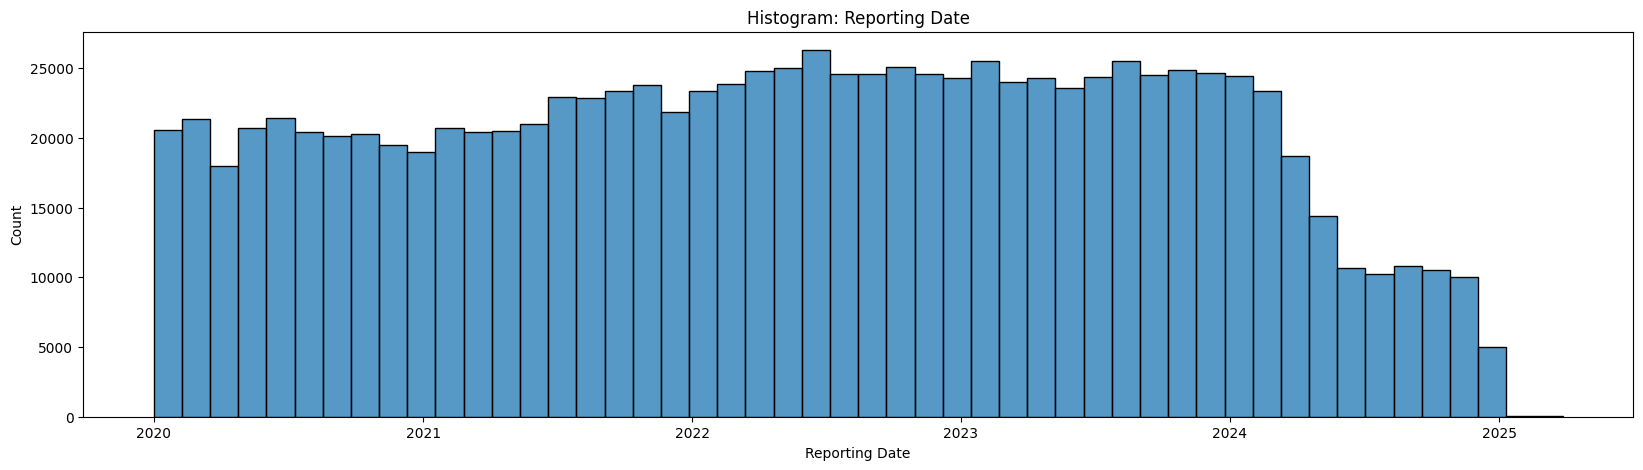

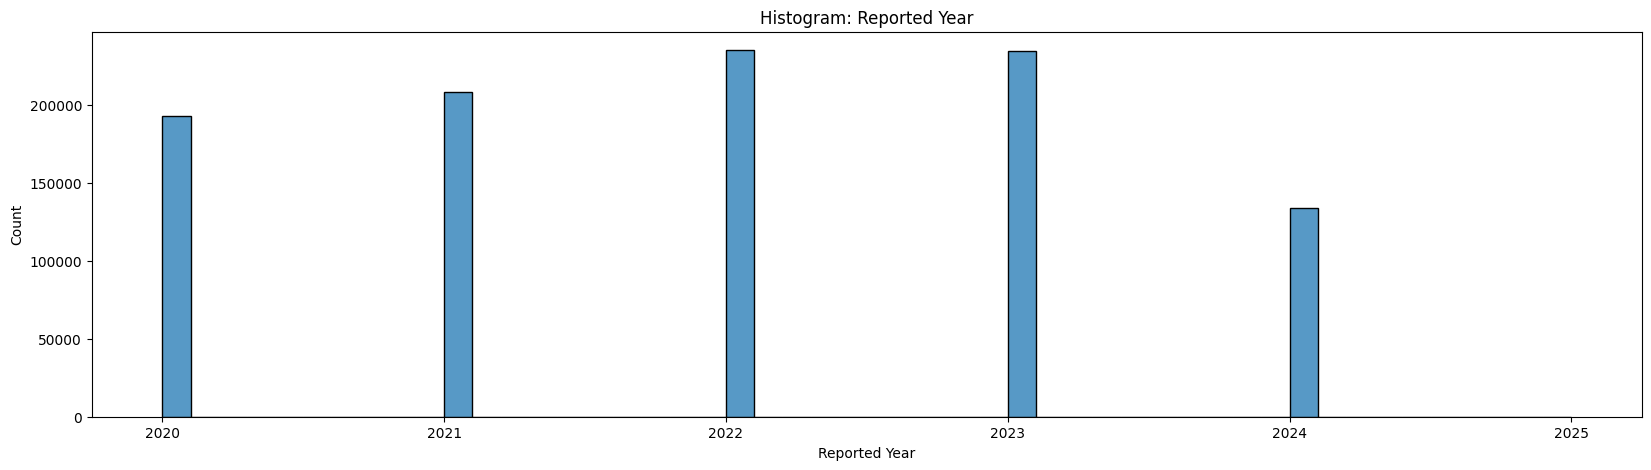

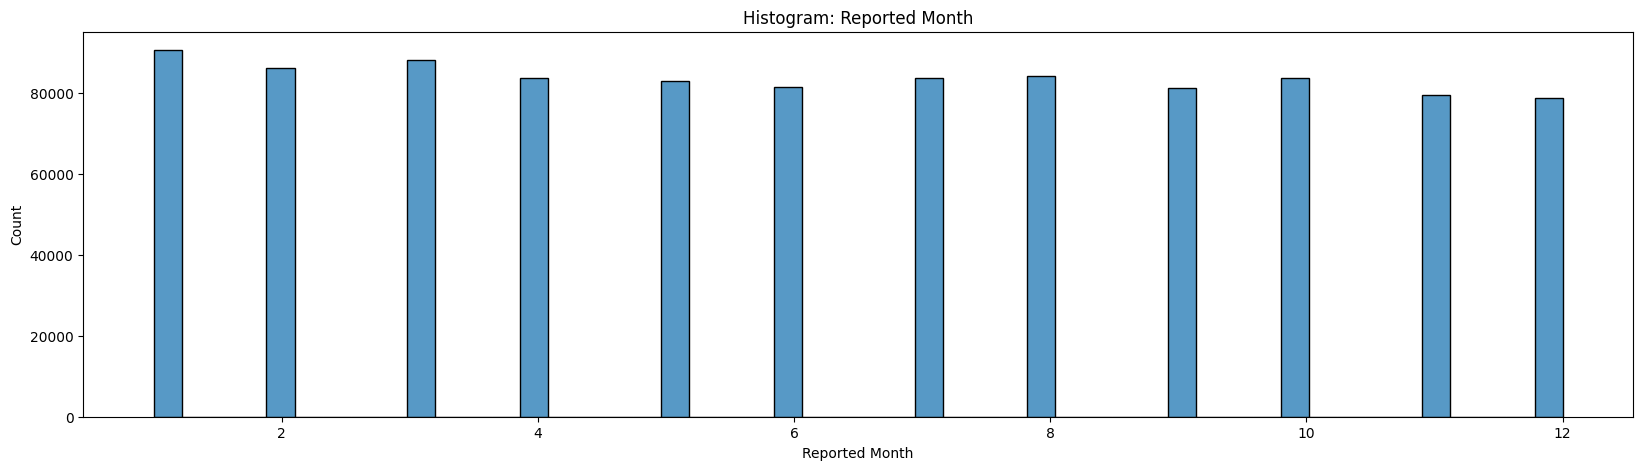

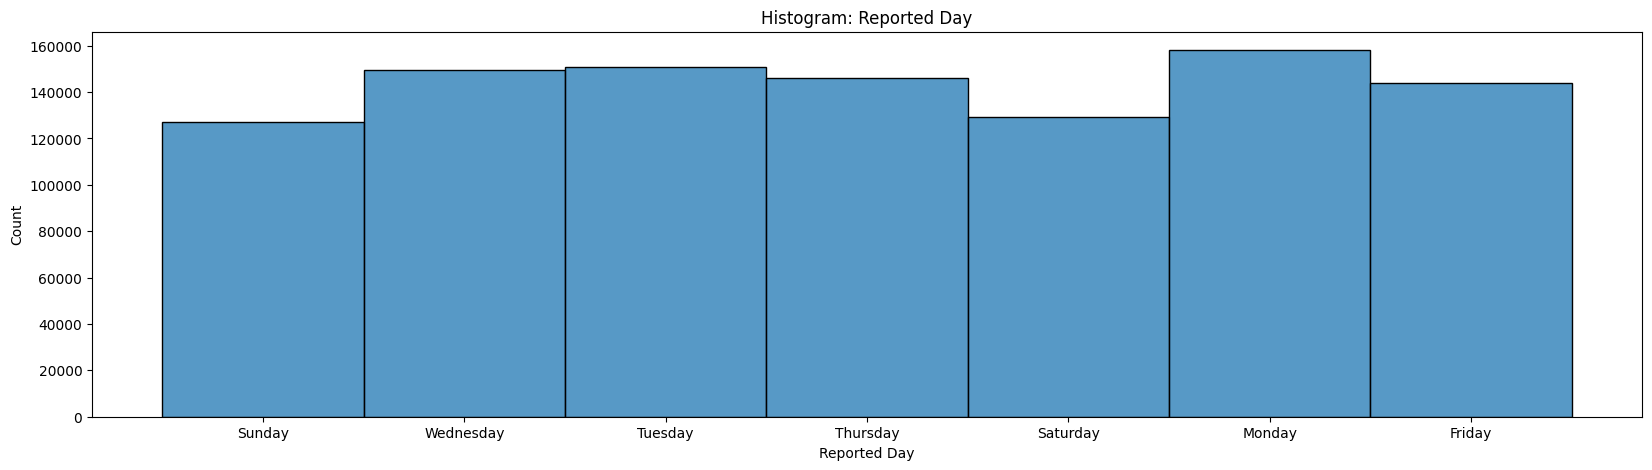

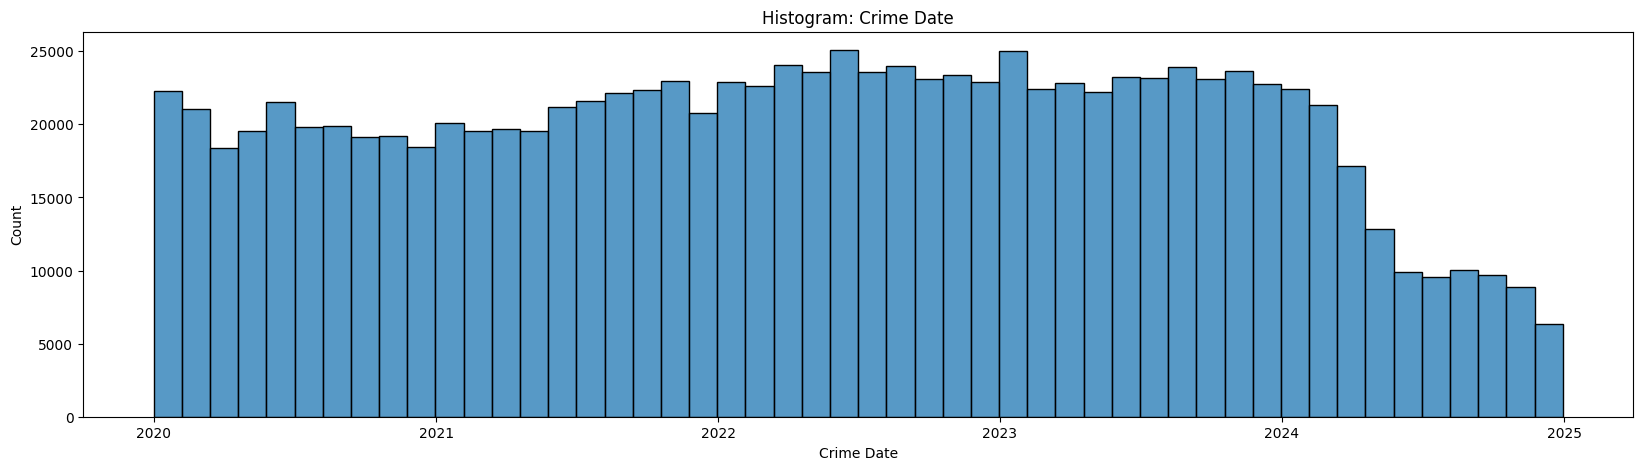

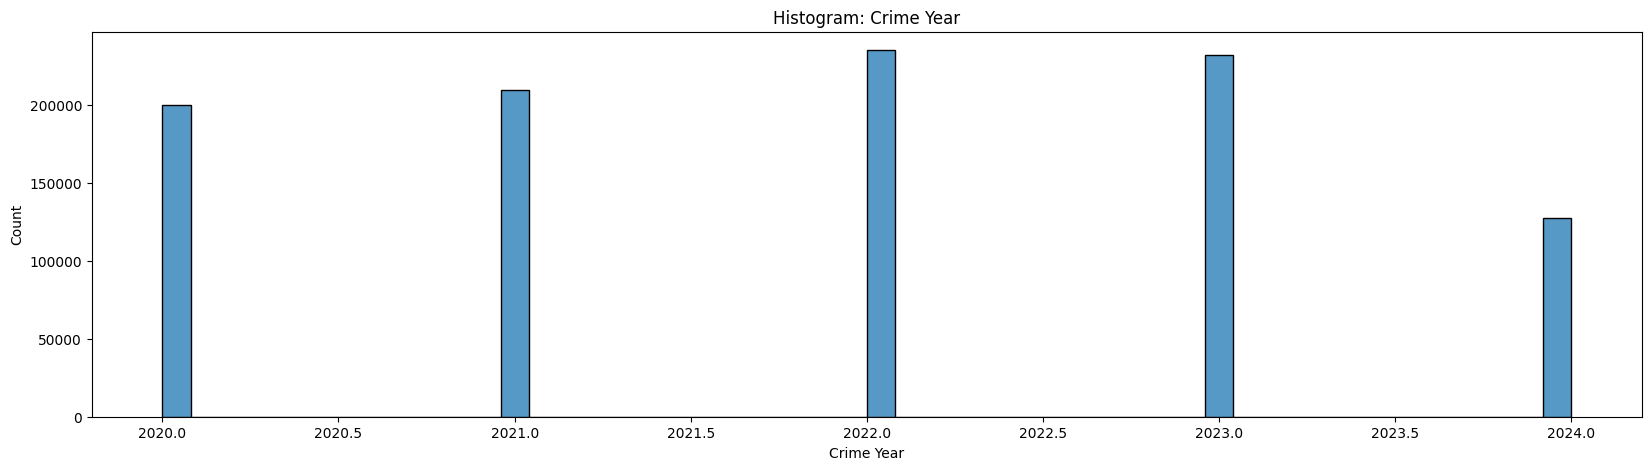

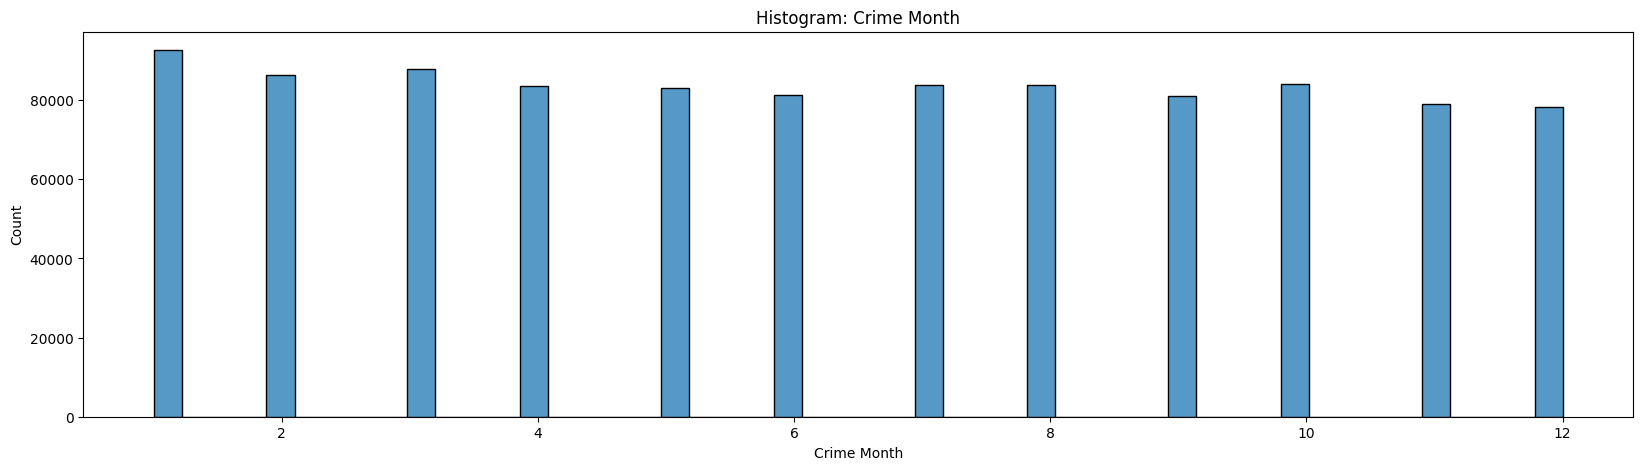

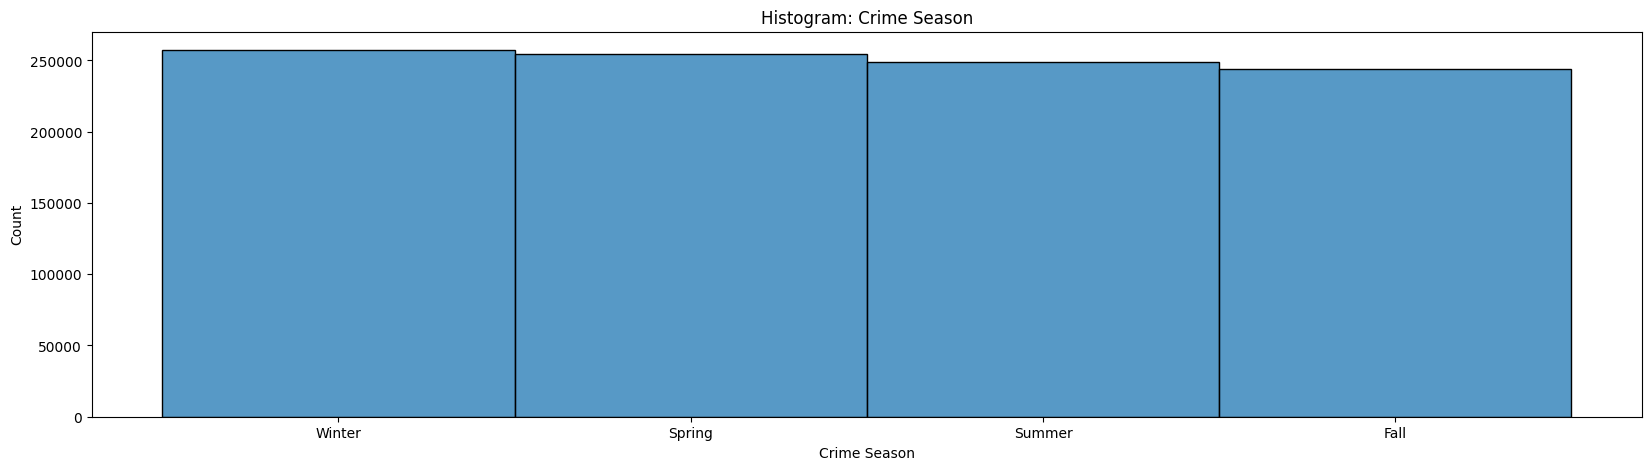

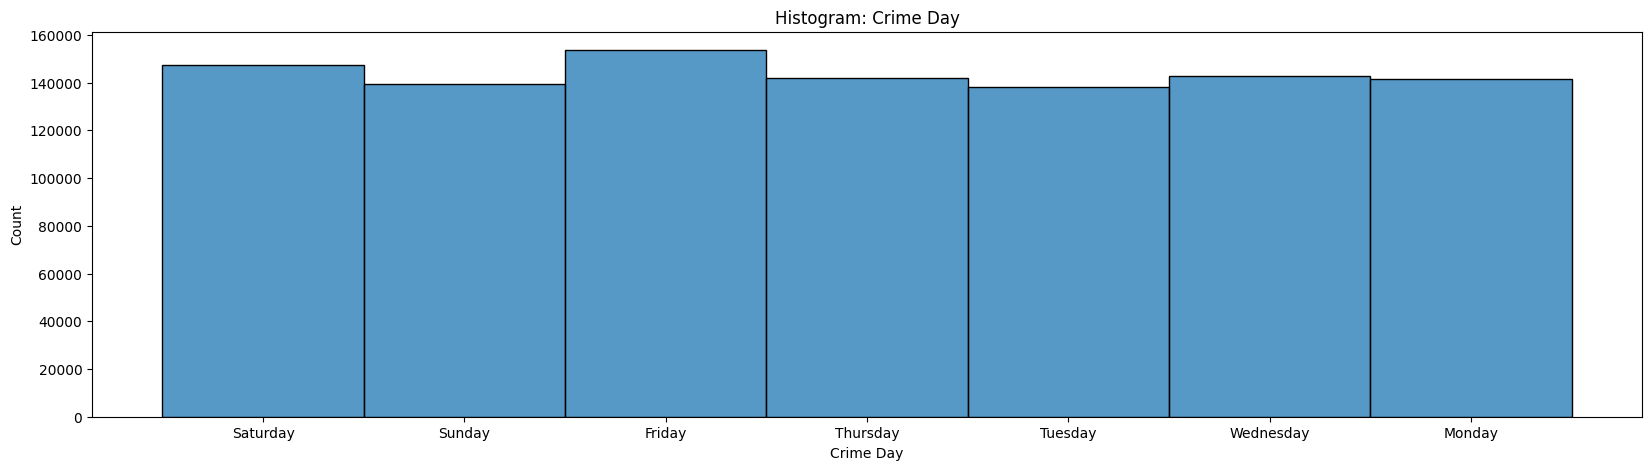

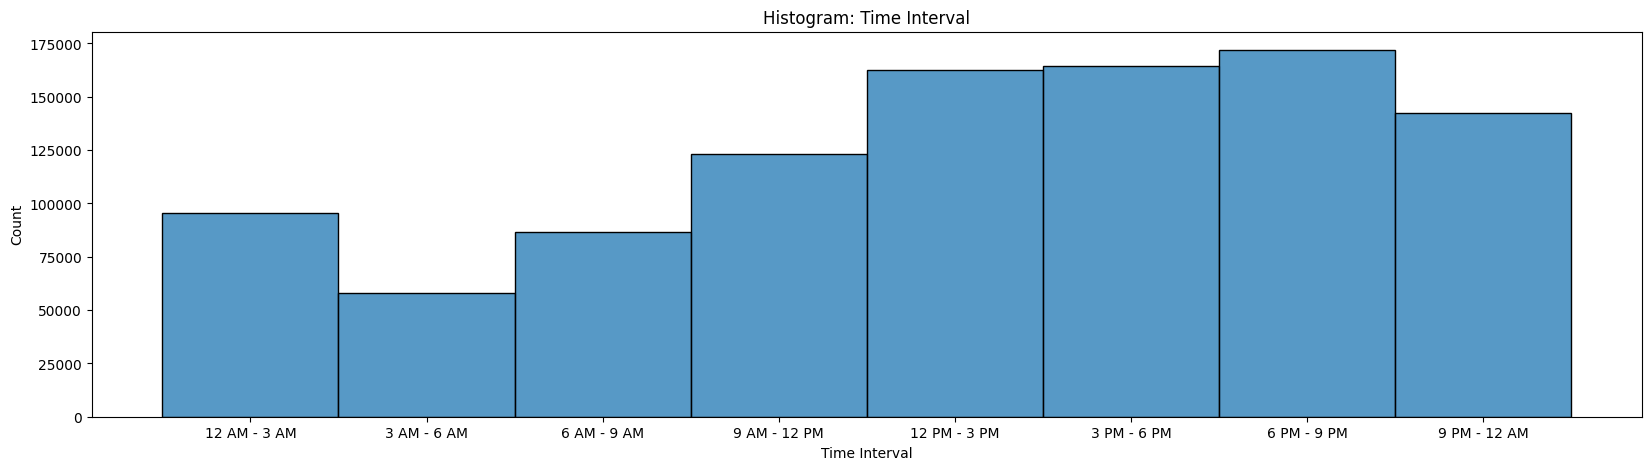

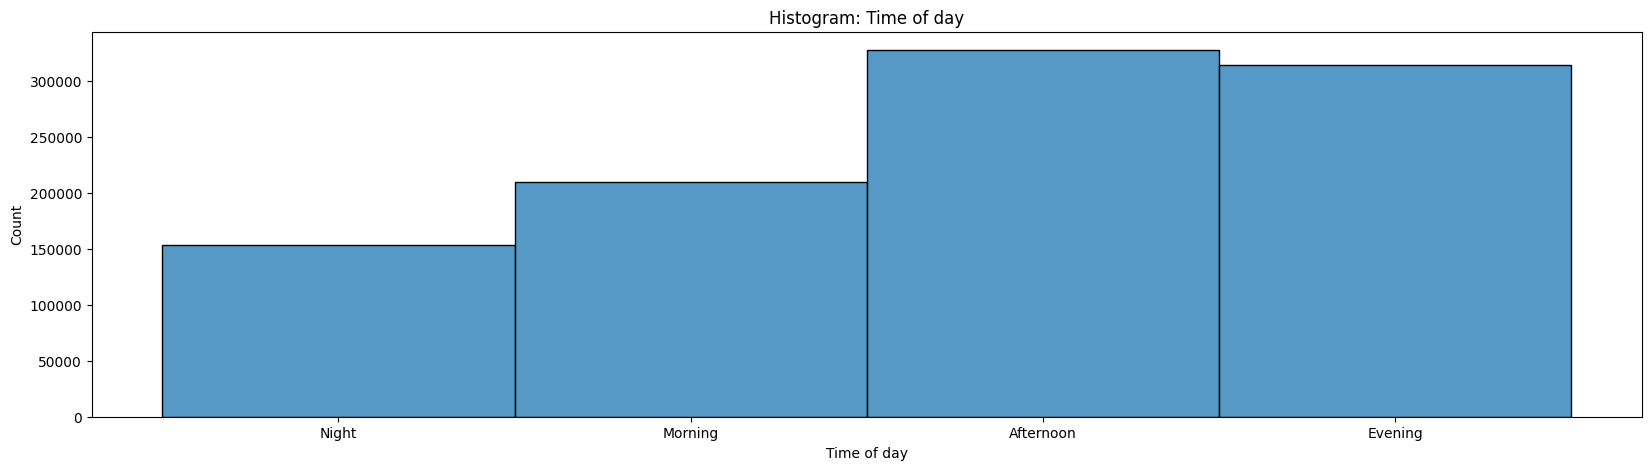

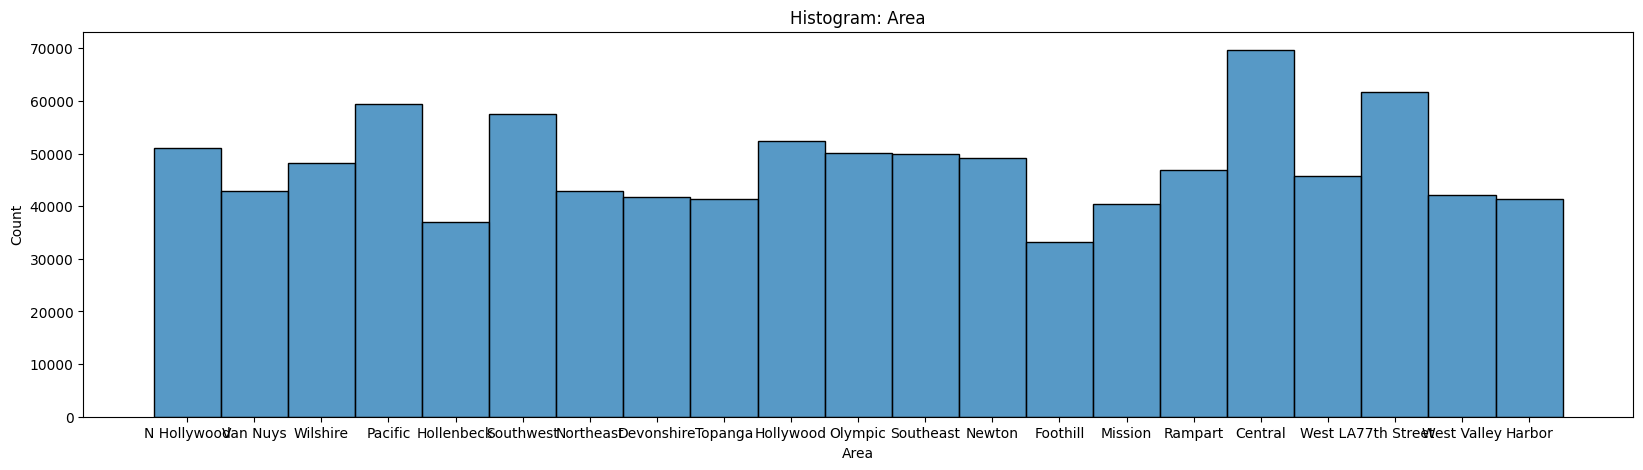

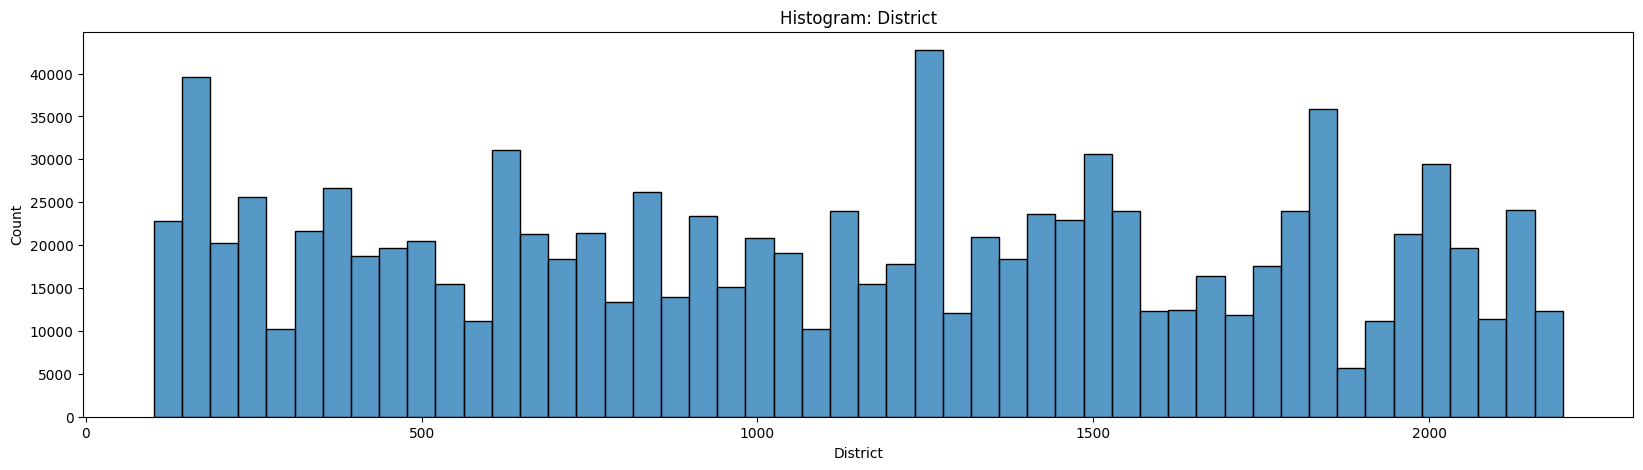

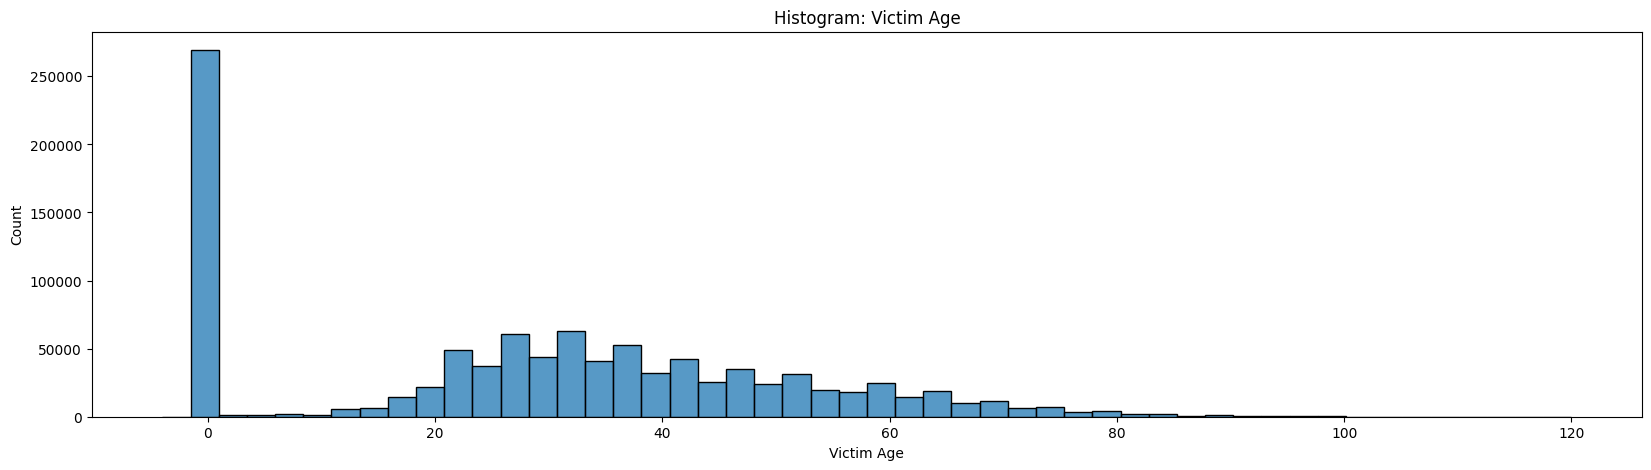

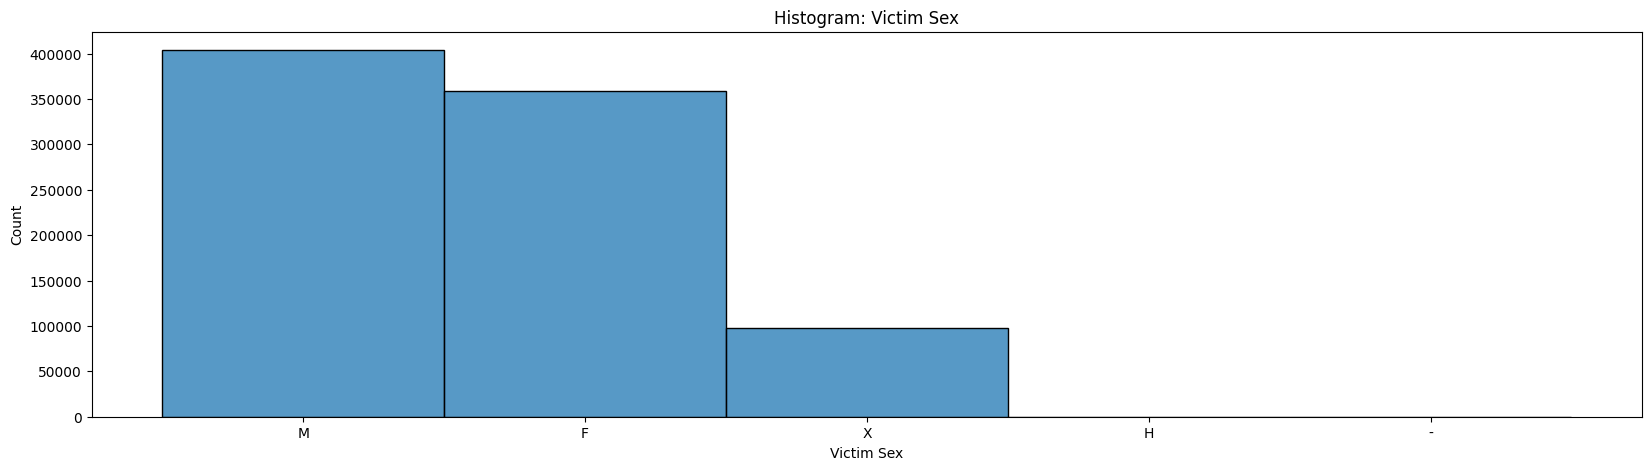

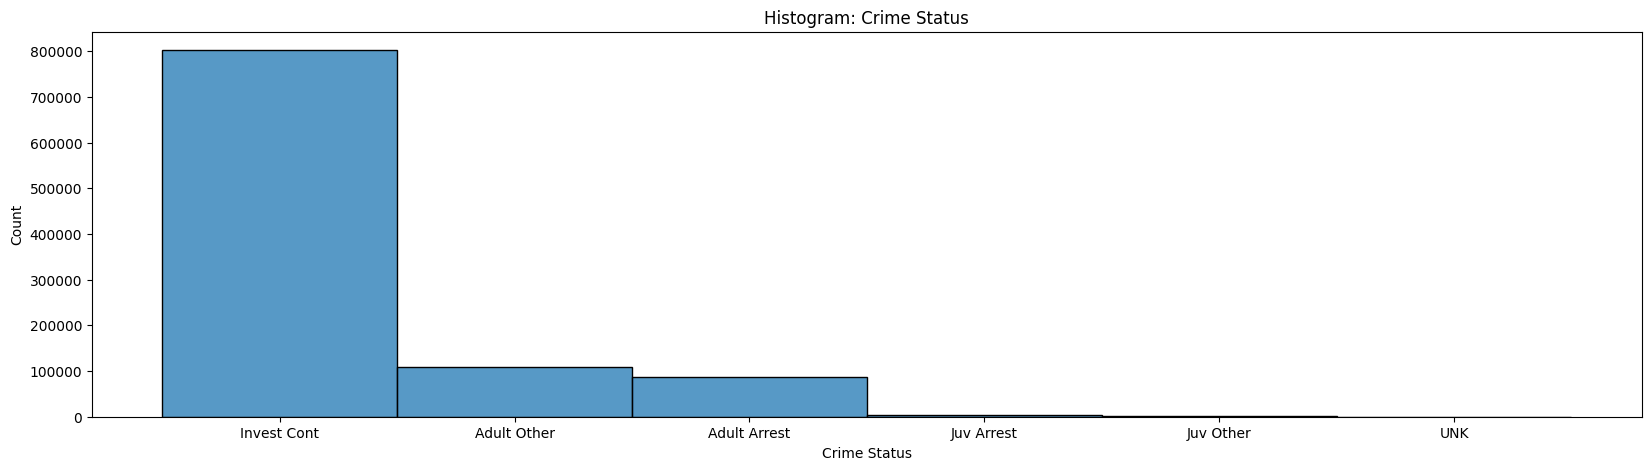

In [20]:
### Checking values
col_list = ['Reporting Date', 'Reported Year', 'Reported Month', 'Reported Day',
            'Crime Date', 'Crime Year', 'Crime Month', 'Crime Season', 'Crime Day', 'Time Interval', 'Time of day',
            'Area', 'District', 'Victim Age', 'Victim Sex', 'Crime Status']

for col in col_list:
    plt.figure(figsize=(20, 5))
    sns.histplot(df[col], bins=50)
    plt.title(f"Histogram: {col}")
    plt.show()
    plt.close()

According to the data description, the dataset contains crime data from 2020–2024. For the reporting year 2024, there is a very large drop compared to previous years, consistent with the LAPD system transition described in the data-source section.

In [21]:
### Removal of incomplete years
print('Records before filtering:', f'{len(df):,}')

df = df[(df['Crime Year'] >= 2020) & (df['Crime Year'] <= 2023)].reset_index(drop=True)

print('Records after filtering to Crime Year 2020-2023:', f'{len(df):,}')

Records before filtering: 1,004,894
Records after filtering to Crime Year 2020-2023: 877,327


In [22]:
### Cleaning coordinates LAT & LON
# Coordinates 0,0 indicate a failed geocoding attempt

zero_coords = ((df['LAT'] == 0) | (df['LON'] == 0)).sum()
print(f'Records with LAT = 0 or LON = 0: {zero_coords:,} '
      f'({zero_coords / len(df) * 100:.2f}% of the dataset)')

df.loc[(df['LAT'] == 0) | (df['LON'] == 0), ['LAT', 'LON']] = np.nan

Records with LAT = 0 or LON = 0: 2,240 (0.26% of the dataset)


Checking for outliers that stood out in the columns: `Crime Time`, `Victim Age` and `Victim Sex`.

In [23]:
### Checking values - details
## Crime Time
print('########## Crime Time ##########')
crime_time = df[df['Crime Time'] == '12:00']
print(crime_time['Main Crime'].value_counts())
print('')
print(crime_time['Main Crime'].unique())

df['Crime Time'] = df['Crime Time'].replace('12:00', np.nan)
mask = df['Crime Time'].isna()
df.loc[mask, ['Time Interval', 'Time of day']] = np.nan

########## Crime Time ##########
Main Crime
THEFT OF IDENTITY                                   5528
VEHICLE - STOLEN                                    3011
BURGLARY                                            2152
THEFT FROM MOTOR VEHICLE - PETTY ($950 & UNDER)     2026
THEFT PLAIN - PETTY ($950 & UNDER)                  1586
                                                    ... 
PURSE SNATCHING                                        1
TILL TAP - GRAND THEFT ($950.01 & OVER)                1
BLOCKING DOOR INDUCTION CENTER                         1
SHOTS FIRED AT MOVING VEHICLE, TRAIN OR AIRCRAFT       1
INCITING A RIOT                                        1
Name: count, Length: 114, dtype: int64

<StringArray>
[                                       'THEFT OF IDENTITY',
                                                 'BURGLARY',
                                         'VEHICLE - STOLEN',
 'THEFT-GRAND ($950.01 & OVER)EXCPT,GUNS,FOWL,LIVESTK,PROD',
                           'VIO

Most of the records for 12:00 are related to theft or burglary, so time is likely listed as the default.\
The time 12:00 will be excluded (replaced by NaN value) from the analyzed data.

In [24]:
### Checking values - details
# Victim Age
print('########## Victim Age ##########')
victim_age = df[df['Victim Age'].isin([120, 0, -1, -2, -3, -4])]
df['Victim Age'] = df['Victim Age'].replace([120, 0, -1, -2, -3, -4], np.nan)

# Displaying Victim Age with Main Crime
victim_age.groupby('Victim Age')['Main Crime'].value_counts()

########## Victim Age ##########


Victim Age  Main Crime                                    
-4          BUNCO, GRAND THEFT                                2
            BATTERY ON A FIREFIGHTER                          1
-3          THEFT PLAIN - PETTY ($950 & UNDER)                2
            THEFT OF IDENTITY                                 1
            SHOPLIFTING - PETTY THEFT ($950 & UNDER)          1
                                                             ..
 0          GRAND THEFT / INSURANCE FRAUD                     1
            RAPE, ATTEMPTED                                   1
            TELEPHONE PROPERTY - DAMAGE                       1
            CONTRIBUTING                                      1
 120        ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT    1
Name: count, Length: 178, dtype: int64

A `Victim Age` of 0 is not necessarily an error in all cases, it most likely means "not applicable", i.e. the crime has no personal victim (vehicle theft, burglary of a location), but still I've decided to replace it with NaN value.

In [25]:
### Displaying Victim Age df (with Age: 120, 0, -1, -2, -3, -4 )
victim_age.sample(min(5, len(victim_age)))

,Crime ID,Reporting Date,Reported Year,Reported Month,Reported Day,Crime Date,Crime Year,Crime Month,Crime Season,Crime Day,Crime Time,Time Interval,Time of day,Area,District,Location,Address,LAT,LON,Victim Age,Victim Sex,Crime Status,Weapon,Main Crime,Additional Crime 1,Additional Crime 2,Additional Crime 3,Additional Crime 4
189245,200413686,2020-10-11,2020,10,Sunday,2020-10-10,2020,10,Fall,Saturday,23:30,9 PM - 12 AM,Evening,Hollenbeck,404,STREET,5500 BUSHNELL WY,34.10,-118.19,0,NaN,Adult Arrest,NaN,VEHICLE - STOLEN,VEHICLE - STOLEN,NaN,NaN,NaN
776071,230815944,2023-10-22,2023,10,Sunday,2023-10-18,2023,10,Fall,Wednesday,08:23,6 AM - 9 AM,Morning,West LA,852,DEPARTMENT STORE,11800 SANTA MONICA BL,34.04,-118.46,0,X,Invest Cont,NaN,SHOPLIFTING - PETTY THEFT ($950 & UNDER),SHOPLIFTING - PETTY THEFT ($950 & UNDER),NaN,NaN,NaN
341591,211700946,2021-12-01,2021,12,Wednesday,2021-12-01,2021,12,Winter,Wednesday,08:50,6 AM - 9 AM,Morning,Devonshire,1722,MARKET,21400 DEVONSHIRE ST,34.26,-118.60,0,X,Adult Arrest,VERBAL THREAT,ROBBERY,ROBBERY,NaN,NaN,NaN
112707,201015167,2020-11-17,2020,11,Tuesday,2020-11-16,2020,11,Fall,Monday,14:00,12 PM - 3 PM,Afternoon,West Valley,1067,STAIRWELL*,5300 BALBOA BL,34.17,-118.51,0,M,Invest Cont,NaN,VANDALISM - MISDEAMEANOR ($399 OR UNDER),VANDALISM - MISDEAMEANOR ($399 OR UNDER),NaN,NaN,NaN
159268,200815891,2020-10-30,2020,10,Friday,2020-10-30,2020,10,Fall,Friday,NaN,NaN,NaN,West LA,824,OTHER BUSINESS,14800 PACIFIC COAST HY,34.04,-118.51,0,M,Invest Cont,ROCK/THROWN OBJECT,BATTERY - SIMPLE ASSAULT,BATTERY - SIMPLE ASSAULT,NaN,NaN,NaN


The distribution of `Main Crime` at age 0 is dominated by categories without a personal victim. The values: 120, 0, -1, -2, -3, -4 have been removed (replaced by NaN value).

In [26]:
### Checking values - details
# Victim Sex
print('########## Victim Sex ##########')
victim_sex = df[df['Victim Sex'].isin(['X', 'H', '-'])]
df['Victim Sex'] = df['Victim Sex'].replace(['X', 'H', '-'], np.nan)

# Displaying Victim Sex with Main Crime
victim_sex.groupby('Victim Sex')['Main Crime'].value_counts()

########## Victim Sex ##########


Victim Sex  Main Crime                                             
-           VANDALISM - FELONY ($400 & OVER, ALL CHURCH VANDALISMS)     1
H           THEFT OF IDENTITY                                          19
            BURGLARY FROM VEHICLE                                      16
            THEFT PLAIN - PETTY ($950 & UNDER)                         12
            BATTERY - SIMPLE ASSAULT                                    7
                                                                       ..
X           TELEPHONE PROPERTY - DAMAGE                                 1
            BIGAMY                                                      1
            PURSE SNATCHING                                             1
            LEWD/LASCIVIOUS ACTS WITH CHILD                             1
            CONTRIBUTING                                                1
Name: count, Length: 154, dtype: int64

In [27]:
### Displaying Victim Sex df (with Sex: X', 'H', '-')
victim_sex.sample(5)

,Crime ID,Reporting Date,Reported Year,Reported Month,Reported Day,Crime Date,Crime Year,Crime Month,Crime Season,Crime Day,Crime Time,Time Interval,Time of day,Area,District,Location,Address,LAT,LON,Victim Age,Victim Sex,Crime Status,Weapon,Main Crime,Additional Crime 1,Additional Crime 2,Additional Crime 3,Additional Crime 4
401854,211100844,2021-07-18,2021,7,Sunday,2021-07-18,2021,7,Summer,Sunday,15:00,3 PM - 6 PM,Afternoon,Northeast,1177,STREET,2600 PEPPER AV,34.09,-118.23,NaN,X,Invest Cont,UNKNOWN FIREARM,DISCHARGE FIREARMS/SHOTS FIRED,DISCHARGE FIREARMS/SHOTS FIRED,NaN,NaN,NaN
675537,230120394,2023-09-22,2023,9,Friday,2023-09-22,2023,9,Fall,Friday,22:30,9 PM - 12 AM,Evening,Central,123,MTA - PURPLE LINE - CIVIC CENTER/GRAND PARK,100 S HILL ST,34.05,-118.25,NaN,X,Invest Cont,NaN,TRESPASSING,TRESPASSING,NaN,NaN,NaN
252084,210307151,2021-03-07,2021,3,Sunday,2021-03-07,2021,3,Spring,Sunday,14:30,12 PM - 3 PM,Afternoon,Southwest,363,DRUG STORE,4000 W MARTIN LUTHER KING JR BL,34.02,-118.34,20.00,X,Invest Cont,NaN,VANDALISM - MISDEAMEANOR ($399 OR UNDER),VANDALISM - MISDEAMEANOR ($399 OR UNDER),NaN,NaN,NaN
151222,200618632,2020-11-28,2020,11,Saturday,2020-11-28,2020,11,Fall,Saturday,01:15,12 AM - 3 AM,Night,Hollywood,666,STREET,SEWARD,34.09,-118.33,NaN,X,Adult Arrest,NaN,FAILURE TO YIELD,FAILURE TO YIELD,NaN,NaN,NaN
53813,201310383,2020-05-04,2020,5,Monday,2020-05-03,2020,5,Spring,Sunday,09:45,9 AM - 12 PM,Morning,Newton,1309,OTHER BUSINESS,2100 E 15TH ST,34.02,-118.23,NaN,X,Invest Cont,NaN,"VANDALISM - FELONY ($400 & OVER, ALL CHURCH VA...","VANDALISM - FELONY ($400 & OVER, ALL CHURCH VA...",NaN,NaN,NaN



The values: X, H, - for `Victim Sex` have been removed (replaced by NaN value) becuase these values will not be useful in the analysis.

**Conclusion:** Records are not deleted simply because they are “unusual”, missing data can be an important business indicator.

#### A Final Look at the Processed Data

In [28]:
### Checking the mean and percentiles to see if there are any outliers after processing
df.describe(percentiles=[0.01, 0.5, 0.7, 0.9, 0.95, 0.999]).T

,count,mean,min,1%,50%,70%,90%,95%,99.9%,max,std
Crime ID,"877,327.00","217,184,110.45",817.00,"200,118,848.52","220,317,555.00","222,001,030.60","231,409,491.20","231,812,730.70","241,907,551.48","252,004,250.00","11,253,703.83"
Reporting Date,877327,2022-02-08 08:43:22.720308,2020-01-01 00:00:00,2020-01-19 00:00:00,2022-03-03 00:00:00,2022-11-28 00:00:00,2023-08-28 00:00:00,2023-11-03 00:00:00,2024-07-19 00:00:00,2025-03-28 00:00:00,NaN
Reported Year,"877,327.00","2,021.61","2,020.00","2,020.00","2,022.00","2,022.00","2,023.00","2,023.00","2,024.00","2,025.00",1.12
Reported Month,"877,327.00",6.54,1.00,1.00,7.00,9.00,11.00,12.00,12.00,12.00,3.44
Crime Date,877327,2022-01-26 04:15:37.916193,2020-01-01 00:00:00,2020-01-15 00:00:00,2022-02-16 00:00:00,2022-11-12 00:00:00,2023-08-16 00:00:00,2023-10-23 00:00:00,2023-12-30 00:00:00,2023-12-31 00:00:00,NaN
Crime Year,"877,327.00","2,021.57","2,020.00","2,020.00","2,022.00","2,022.00","2,023.00","2,023.00","2,023.00","2,023.00",1.11
Crime Month,"877,327.00",6.54,1.00,1.00,7.00,9.00,11.00,12.00,12.00,12.00,3.44
District,"877,327.00","1,117.33",101.00,122.00,"1,141.00","1,511.00","1,985.00","2,069.00","2,189.00","2,199.00",609.88
LAT,"875,087.00",34.07,33.71,33.74,34.06,34.12,34.22,34.25,34.32,34.33,0.11
LON,"875,087.00",-118.35,-118.67,-118.61,-118.32,-118.28,-118.25,-118.22,-118.17,-118.16,0.10


The latest additional columns in the final dataset

In [29]:
#### Adding additional columns to the table
# creating a column indicating whether the weapon was used: Yes / No
df['Weapon Reported'] = df['Weapon'].notna().map({True: 'Yes', False: 'No'})

# create a column showing the number of crimes within a single report
crime_cols = [
    'Main Crime',
    'Additional Crime 1',
    'Additional Crime 2',
    'Additional Crime 3',
    'Additional Crime 4'
]

# Column containing the number of reported crimes: number of non-empty columns
df['No. of Associated Crimes'] = df[crime_cols].notna().sum(axis=1)

# Column containing the number of unique reported crimes: number of non-empty columns, but if the same crime is in col Additional Crime 4 and Main Crime count it as 1
df['No. of Unique Associated Crimes'] = (
    df[crime_cols]
    .apply(lambda row: row.dropna().unique().size, axis=1)
)

# Columns showing the delay with which crimes are reported
df['Delay in Days'] = (df['Reporting Date'] - df['Crime Date']).dt.days
df['Delay in Months'] = ((df['Reporting Date'] - df['Crime Date']).dt.days/ 30)
df['Delay in Months'] = df['Delay in Months'].round(0)

df.head()

,Crime ID,Reporting Date,Reported Year,Reported Month,Reported Day,Crime Date,Crime Year,Crime Month,Crime Season,Crime Day,Crime Time,Time Interval,Time of day,Area,District,Location,Address,LAT,LON,Victim Age,Victim Sex,Crime Status,Weapon,Main Crime,Additional Crime 1,Additional Crime 2,Additional Crime 3,Additional Crime 4,Weapon Reported,No. of Associated Crimes,No. of Unique Associated Crimes,Delay in Days,Delay in Months
0,211507896,2021-04-11,2021,4,Sunday,2020-11-07,2020,11,Fall,Saturday,08:45,6 AM - 9 AM,Morning,N Hollywood,1502,SINGLE FAMILY DWELLING,7800 BEEMAN AV,34.21,-118.41,31.00,M,Invest Cont,NaN,THEFT OF IDENTITY,THEFT OF IDENTITY,NaN,NaN,NaN,No,2,1,155,5.00
1,201516622,2020-10-21,2020,10,Wednesday,2020-10-18,2020,10,Fall,Sunday,18:45,6 PM - 9 PM,Evening,N Hollywood,1521,SIDEWALK,ATOLL AV,34.20,-118.42,32.00,M,Invest Cont,KNIFE WITH BLADE 6INCHES OR LESS,"ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT","ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT",NaN,NaN,NaN,Yes,2,1,3,0.00
2,240913563,2024-12-10,2024,12,Tuesday,2020-10-30,2020,10,Fall,Friday,12:40,12 PM - 3 PM,Afternoon,Van Nuys,933,SINGLE FAMILY DWELLING,14600 SYLVAN ST,34.18,-118.45,30.00,M,Invest Cont,NaN,THEFT OF IDENTITY,THEFT OF IDENTITY,NaN,NaN,NaN,No,2,1,1502,50.00
3,210704711,2020-12-24,2020,12,Thursday,2020-12-24,2020,12,Winter,Thursday,13:10,12 PM - 3 PM,Afternoon,Wilshire,782,STREET,6000 COMEY AV,34.03,-118.37,47.00,F,Invest Cont,NaN,THEFT FROM MOTOR VEHICLE - GRAND ($950.01 AND ...,THEFT FROM MOTOR VEHICLE - GRAND ($950.01 AND ...,NaN,NaN,NaN,No,2,1,0,0.00
4,201418201,2020-10-03,2020,10,Saturday,2020-09-29,2020,9,Fall,Tuesday,18:30,6 PM - 9 PM,Evening,Pacific,1454,ALLEY,4700 LA VILLA MARINA,33.98,-118.44,63.00,M,Invest Cont,NaN,THEFT FROM MOTOR VEHICLE - PETTY ($950 & UNDER),THEFT FROM MOTOR VEHICLE - PETTY ($950 & UNDER),NaN,NaN,NaN,No,2,1,4,0.00


**Conclusion:**

The columns `Time Interval`, `Time of day`, `Crime Season`, `Crime Day`, `Delay in Days`, `Delay in Months`, `No. of Associated Crimes` and `No. of Unique Associated Crimes` are not used in the current version of the analysis. They are kept in the dataset deliberately, not by oversight, the project is intended to be extended in the future, and these columns are preparation for later stages:

- `Time Interval`, `Time of day`, `Crime Day`: time-of-day and day-of-week analysis (an area × time-of-day heatmap),
- `Crime Season`: quarterly seasonality, complementing the monthly seasonality used in the forecast,
- `Delay in Days`, `Delay in Months`: analysis of reporting delay, also relevant for assessing data completeness at the end of the period,
- `No. of Associated Crimes`, `No. of Unique Associated Crimes`: analysis of co-occurring crime types within a single report.

Keeping these columns does not affect the results of the current analysis, they are not used in any grouping, filter, or model.

# Part Three: Explorative Data Analysis

Analysis of a dataset to summarize its main characteristics, detect patterns, identify previously undetected anomalies, and verify assumptions before proceeding with further analysis.

In [30]:
# Colors
dark_red = '#8B0000'

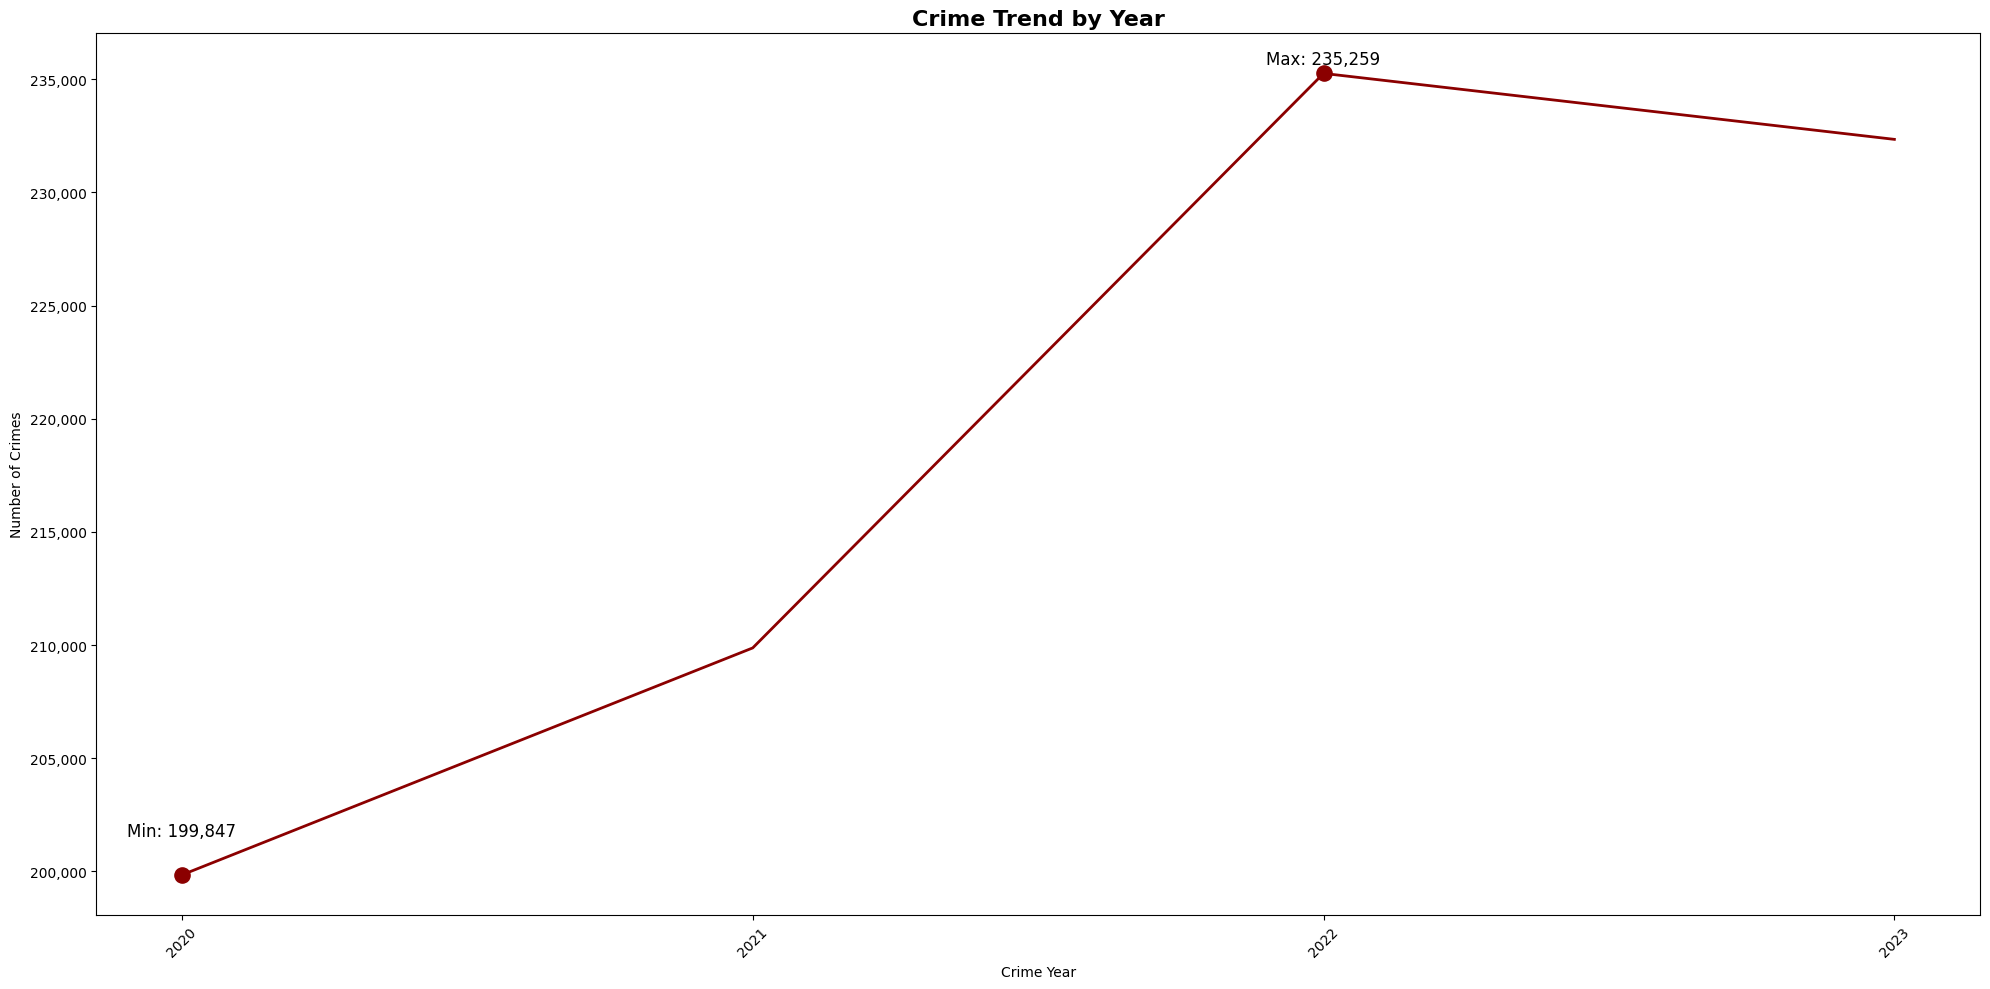

In [31]:
### Crime Years

# Crime Year formatting
df['Crime Year'] = df['Crime Year'].astype(int)

# No. of Crimes aggregated for Crime Year
crime_year = (df.groupby(['Crime Year'])['Crime ID'].count().sort_index())

# Figure
plt.figure(figsize=(20, 10))

# Axis
x_labels = [f"{y}" for y in crime_year.index] 
y = crime_year.values
x = range(len(x_labels))

# Plot
plt.plot(x, y, color = dark_red, linewidth = 2, label = 'Crimes')
plt.xticks(list(x)[::], x_labels[::], rotation=45)

# Max / Min Values
max_i = y.argmax()
min_i = y.argmin()

# Displaying Max/Min on Plot
plt.scatter(max_i, y[max_i], color = dark_red, s = 120, zorder = 5)
plt.scatter(min_i, y[min_i], color = dark_red, s = 120, zorder = 5)

offset = max(y) * 0.01
offset2 = max(y) * 0.001

plt.text(max_i, y[max_i] + offset2, f'Max: {y[max_i]:,}', ha='center', va='bottom', fontsize=12)
plt.text(min_i, y[min_i] + offset, f'Min: {y[min_i]:,}', ha='center', va='top', fontsize=12)

# Formatting axis Y
plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{int(x):,}'))

# Title
plt.title('Crime Trend by Year', fontsize = 16, fontweight = 'bold')

# Labels
plt.xlabel('Crime Year')
plt.ylabel('Number of Crimes')

# Display Chart
plt.tight_layout()
plt.show()

**Conclusion:** From 2020 to 2022, we have observed a marked increase in the number of crimes. This may indicate a gradual resumption of social activity following the pandemic and an increase in residents' mobility.

The year 2022 saw the highest number of crimes in the analyzed period. It is worth examining in further detail which types of offenses were most prevalent that year.

In 2023, there was a slight decrease in the number of crimes compared to 2022. This may suggest that the situation has stabilized or that preventive measures have become more effective.

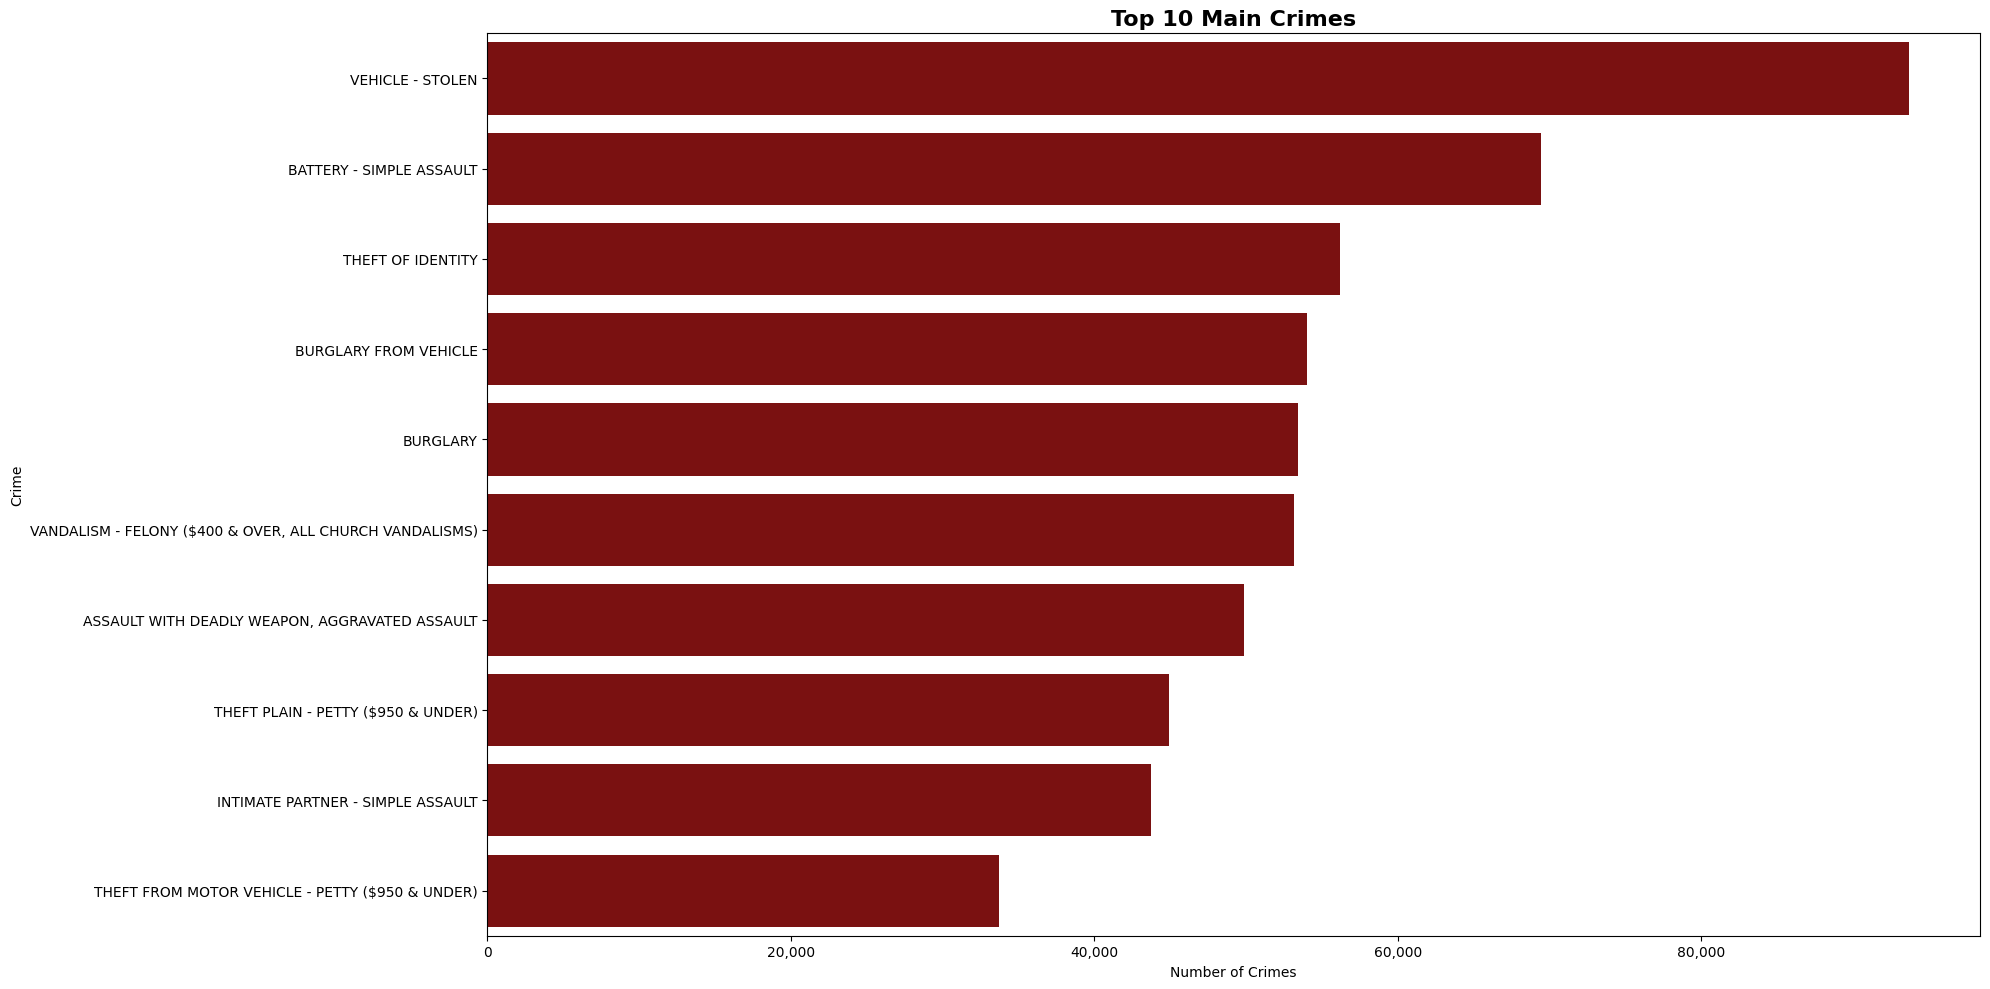

In [32]:
### Top 10 Main Crimes

top_crimes = (df.groupby(['Main Crime'])['Crime ID'].count().sort_values(ascending=False)).head(10)

plt.figure(figsize = (20, 10))
sns.barplot(y = top_crimes.index, x = top_crimes.values, color = dark_red)

plt.gca().xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{int(x):,}'))
plt.title('Top 10 Main Crimes', fontsize = 16, fontweight = 'bold')
plt.xlabel('Number of Crimes')
plt.ylabel('Crime')
plt.tight_layout()
plt.show()

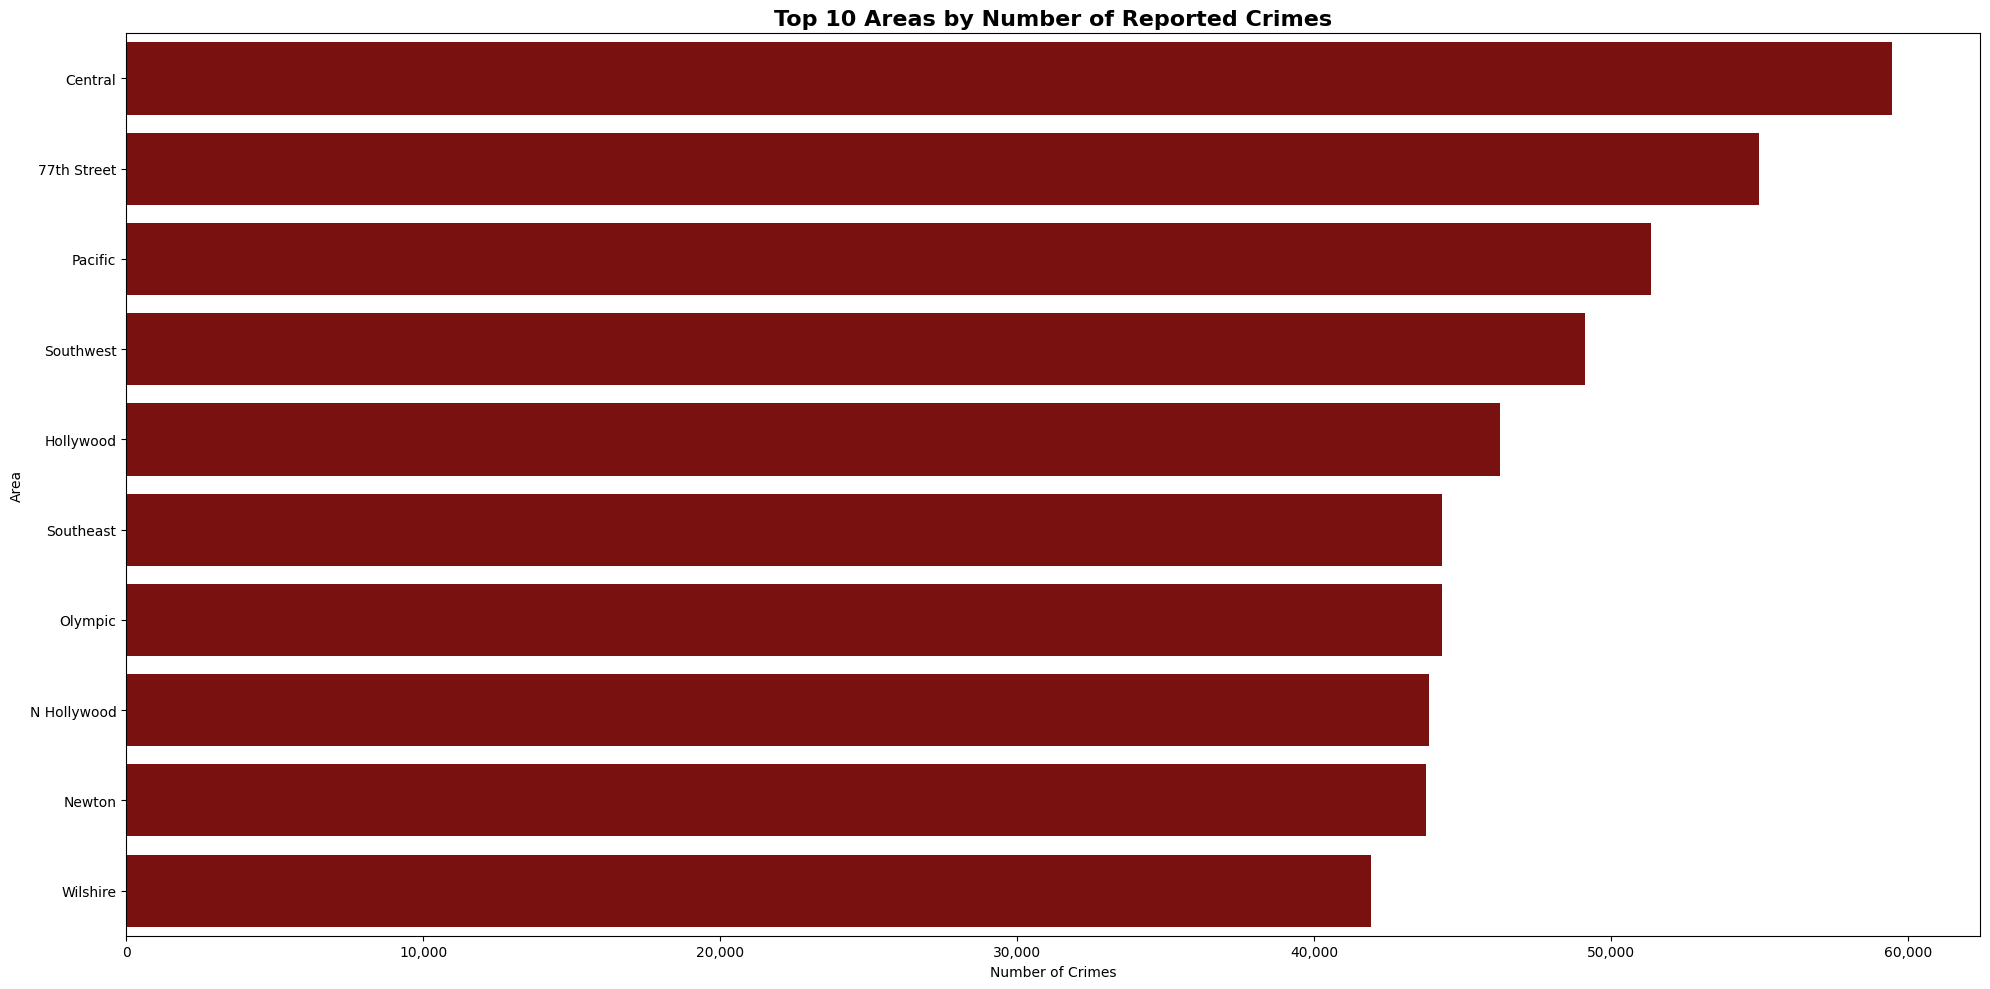

In [33]:
### Top 10 Areas

top_areas = (df.groupby(['Area'])['Crime ID'].count().sort_values(ascending=False)).head(10)

plt.figure(figsize = (20, 10))
sns.barplot(y = top_areas.index, x = top_areas.values, color = dark_red)

plt.gca().xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{int(x):,}'))

plt.title('Top 10 Areas by Number of Reported Crimes', fontsize = 16, fontweight = 'bold')
plt.xlabel('Number of Crimes')
plt.ylabel('Area')
plt.tight_layout()
plt.show()

# Part Four: Where Does Crime Concentrate?

**Business question 1:** which areas of Los Angeles account for roughly 80% of reported crimes?

The analysis is carried out at three levels of aggregation, because the answer depends on the chosen level:

1. **area** (`Area`, 21 units) - management level,
2. **reporting district** (`District`) - operational level,
3. **crime type** (`Main Crime`) - thematic level.

In [34]:
# Colors
grey = '#7A7A7A'

In [35]:
### Pareto / ABC function
def pareto_abc(data, col, a_cut=80, b_cut=95):

    """Returns a table with crime count, share, cumulative share 
    and ABC Classification for any given dimension."""

    out = (data.groupby(col)
               .size()
               .reset_index(name='Crime Count')
               .sort_values('Crime Count', ascending=False)
               .reset_index(drop=True))

    total = out['Crime Count'].sum()
    out['Share %'] = out['Crime Count'] / total * 100
    out['Cumulative %'] = out['Crime Count'].cumsum() / total * 100
    out['ABC'] = np.select(
        [out['Cumulative %'] <= a_cut, out['Cumulative %'] <= b_cut],
        ['A', 'B'], default='C')
    
    return out

### 4.1 Area Level

In [36]:
### 4.1 Area level
area_summary = pareto_abc(df, 'Area')
areas_A = area_summary.loc[area_summary['ABC'] == 'A', 'Area'].tolist()

print(f'Number of areas: {len(area_summary)}')

print(f'Segment A: {len(areas_A)} areas '
      f'({len(areas_A)/len(area_summary)*100:.0f}% of all units) '
      f'= {area_summary.loc[area_summary['ABC']=='A','Share %'].sum():.1f}% of crimes')

print(f'Largest area: {area_summary.loc[0,'Area']} '
      f'({area_summary.loc[0,'Share %']:.2f}% of the total)')

area_summary

Number of areas: 21
Segment A: 15 areas (71% of all units) = 76.7% of crimes
Largest area: Central (6.78% of the total)


,Area,Crime Count,Share %,Cumulative %,ABC
0,Central,59456,6.78,6.78,A
1,77th Street,54981,6.27,13.04,A
2,Pacific,51351,5.85,18.90,A
3,Southwest,49127,5.60,24.50,A
4,Hollywood,46277,5.27,29.77,A
5,Southeast,44325,5.05,34.82,A
6,Olympic,44300,5.05,39.87,A
7,N Hollywood,43858,5.00,44.87,A
8,Newton,43787,4.99,49.86,A
9,Wilshire,41933,4.78,54.64,A


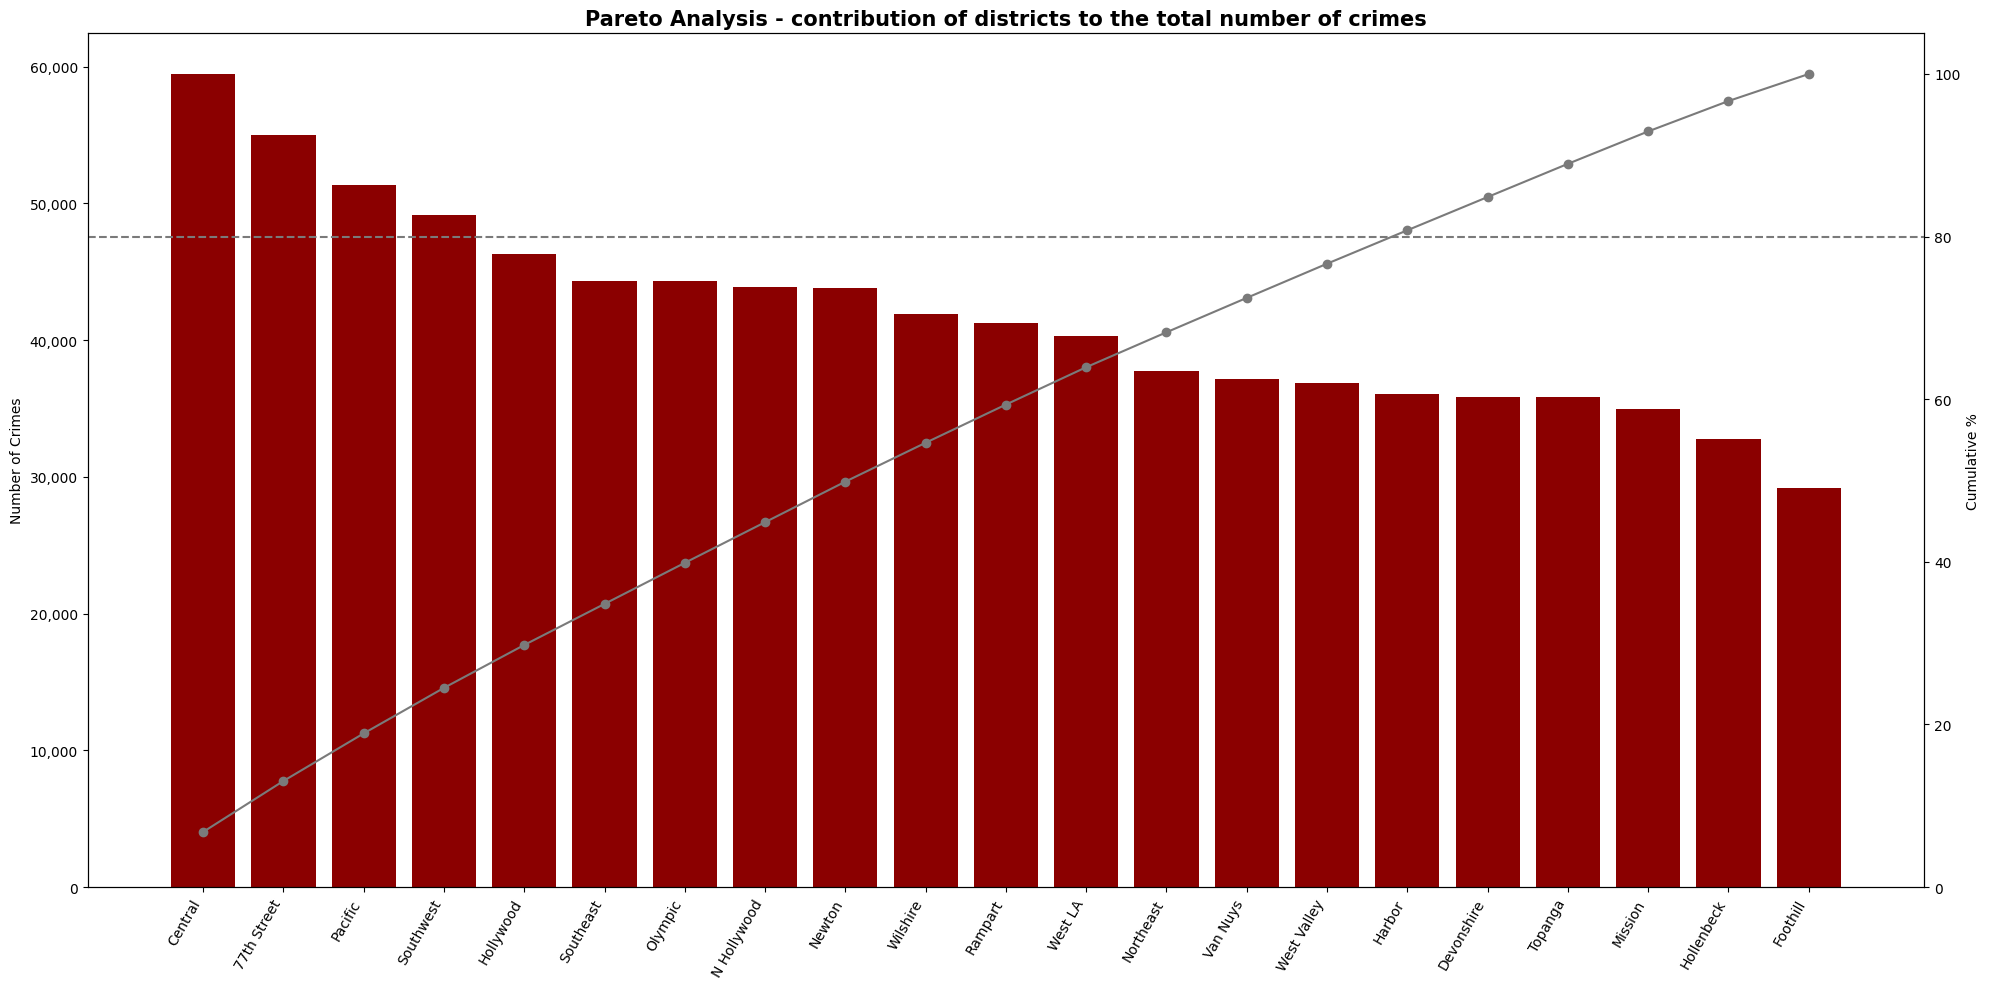

In [37]:
### 4.1 Pareto chart - Areas
fig, ax1 = plt.subplots(figsize=(20, 10))
x = np.arange(len(area_summary))

ax1.bar(x, area_summary['Crime Count'], color=dark_red)
ax1.set_xticks(x)
ax1.set_xticklabels(area_summary['Area'], rotation=60, ha='right')
ax1.set_ylabel('Number of Crimes')
ax1.yaxis.set_major_formatter(ticker.FuncFormatter(lambda v, p: f'{int(v):,}'))

ax2 = ax1.twinx()
ax2.plot(x, area_summary['Cumulative %'], marker='o', color=grey)
ax2.axhline(80, linestyle='--', color=grey)
ax2.set_ylabel('Cumulative %')
ax2.set_ylim(0, 105)

plt.title('Pareto Analysis - contribution of districts to the total number of crimes',
          fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

### 4.2 District Level

In [38]:
### 4.2 District level — does concentration appear here?
district_summary = pareto_abc(df, 'District')
n_A = (district_summary['ABC'] == 'A').sum()

print(f'Number of districts: {len(district_summary)}')

print(f'Segment A: {n_A} districts ({n_A/len(district_summary)*100:.1f}% of units) '
      f'= {district_summary.loc[district_summary['ABC']=='A','Share %'].sum():.1f}% of crimes')

print(f'Largest area: {district_summary.loc[0,'District']} '
      f'({district_summary.loc[0,'Share %']:.2f}% of the total)')

Number of districts: 1207
Segment A: 622 districts (51.5% of units) = 80.0% of crimes
Largest area: 162 (0.53% of the total)


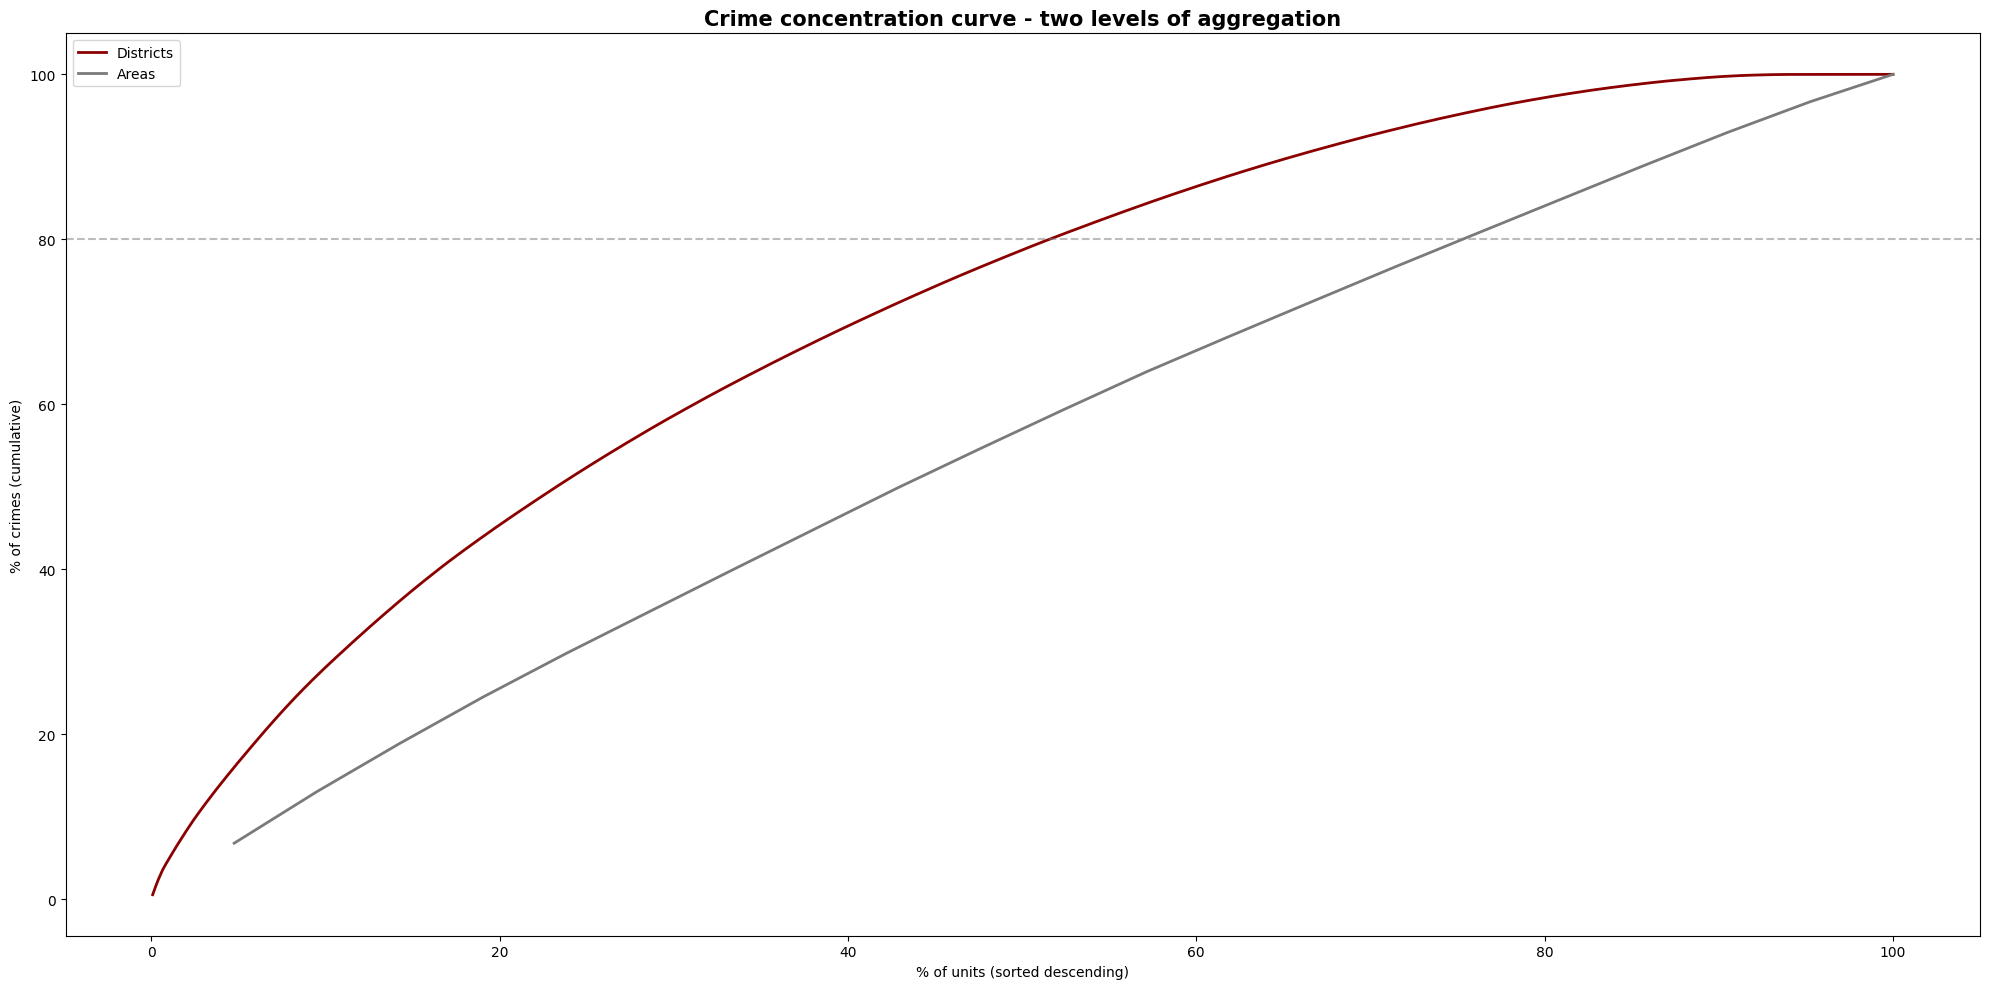

,District,Crime Count,Share %,Cumulative %,ABC
0,162,4672,0.53,0.53,A
1,645,4336,0.49,1.03,A
2,182,4180,0.48,1.50,A
3,1494,4069,0.46,1.97,A
4,646,3838,0.44,2.40,A
5,636,3523,0.40,2.81,A
6,111,3383,0.39,3.19,A
7,2156,3352,0.38,3.57,A
8,1822,2890,0.33,3.90,A
9,152,2654,0.30,4.21,A


In [39]:
### 4.2 Concentration Curve
plt.figure(figsize=(20, 10))

plt.plot(np.arange(1, len(district_summary) + 1) / len(district_summary) * 100,
         district_summary['Cumulative %'], color=dark_red, linewidth=2,
         label='Districts')

plt.plot(np.arange(1, len(area_summary) + 1) / len(area_summary) * 100,
         area_summary['Cumulative %'], color=grey, linewidth=2,
        label='Areas')


plt.axhline(80, color=grey, linestyle='--', alpha=0.5)

plt.xlabel('% of units (sorted descending)')
plt.ylabel('% of crimes (cumulative)')

plt.title('Crime concentration curve - two levels of aggregation',
          fontsize=15, fontweight='bold')

plt.legend()
plt.tight_layout()
plt.show()

district_summary.head(20)

### 4.3 Crime Level

In [40]:
### 4.3 Crime Level
crime_type_summary = pareto_abc(df, 'Main Crime')
n_A_ct = (crime_type_summary['ABC'] == 'A').sum()

print(f'Number of crime types: {len(crime_type_summary)}')

print(f'Segment A: {n_A_ct} types ({n_A_ct/len(crime_type_summary)*100:.1f}% of categories) '
      f'= {crime_type_summary.loc[crime_type_summary['ABC']=='A','Share %'].sum():.1f}% of crimes')

print(f'The Most Common Crime: {crime_type_summary.loc[0,'Main Crime']} '
      f'({crime_type_summary.loc[0,'Share %']:.2f}% of the total)')

crime_type_summary.head(15)

Number of crime types: 138
Segment A: 15 types (10.9% of categories) = 78.3% of crimes
The Most Common Crime: VEHICLE - STOLEN (10.68% of the total)


,Main Crime,Crime Count,Share %,Cumulative %,ABC
0,VEHICLE - STOLEN,93674,10.68,10.68,A
1,BATTERY - SIMPLE ASSAULT,69421,7.91,18.59,A
2,THEFT OF IDENTITY,56216,6.41,25.00,A
3,BURGLARY FROM VEHICLE,53990,6.15,31.15,A
4,BURGLARY,53411,6.09,37.24,A
5,"VANDALISM - FELONY ($400 & OVER, ALL CHURCH VA...",53141,6.06,43.30,A
6,"ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT",49828,5.68,48.98,A
7,THEFT PLAIN - PETTY ($950 & UNDER),44898,5.12,54.09,A
8,INTIMATE PARTNER - SIMPLE ASSAULT,43717,4.98,59.08,A
9,THEFT FROM MOTOR VEHICLE - PETTY ($950 & UNDER),33702,3.84,62.92,A


# Conclusion: 
## a negative result that is still a result

The Pareto rule **does not hold at the area level**: Segment A spans 15 of 21 units, and the largest area is less than twice the size of the smallest.

**Management implication:** a list of "priority areas" covering 71% of units is not a prioritization. To obtain a useful operational priority, concentration must be sought at a lower level of aggregation (reporting district) or in a different dimension (crime type).

**Limitation:** LAPD areas are not equal in size or population, so a comparable volume of crime does not imply comparable per-capita risk.
Where the 80/20 effect actually shows up

Comparing the three levels of aggregation shows where concentration genuinely occurs. The curve for reporting districts sits clearly above the curve for areas - the further from the diagonal, the stronger the concentration.

15 areas (71% of all units) = 76.7% of crimes\
Largest area: Central (6.78% of the total)

622 districts (51.5% of units) = 80.0% of crimes\
Largest area: 162 (0.53% of the total)

15 types (10.9% of categories) = 78.3% of crimes\
The Most Common Crime: VEHICLE - STOLEN (10.68% of the total)

# Part Five: How Is Crime Changing Over Time?

**Business question 2:** which areas show an increase, decrease, or stabilization between 2020 and 2023?

**Methodological problem to resolve before analysis:** 2020 was a pandemic year with reduced mobility, so it is an artificially depressed baseline. A change computed only as 2020 vs 2023 systematically overstates growth.

The trend is therefore described using three independent measures:

- change 2020 vs 2023 (the original measure),
- change 2021 vs 2023 (controls for the pandemic baseline),

An area is classified as increasing or decreasing **only when all three measures agree in direction**. Otherwise the trend is labelled ambiguous.

In [41]:
### Working dataset for the following parts
crime_A = df[df['Area'].isin(areas_A)].copy()

print(f'Segment A: {len(areas_A)} areas, {len(crime_A):,} records '
      f'({len(crime_A)/len(df)*100:.1f}% of the dataset)')

Segment A: 15 areas, 672,620 records (76.7% of the dataset)


In [42]:
### 5.1 Two trend measures
years = [2020, 2021, 2022, 2023]

trend_A = (crime_A.groupby(['Area', 'Crime Year'])['Crime ID']
                  .count()
                  .unstack(fill_value=0)
                  .reindex(columns=years, fill_value=0))

trend_A['Change 2020-2023 %'] = (trend_A[2023] - trend_A[2020]) / trend_A[2020] * 100
trend_A['Change 2021-2023 %'] = (trend_A[2023] - trend_A[2021]) / trend_A[2021] * 100

THRESHOLD = 5.0   # practical significance threshold, in percentage points

def classify(r):
    signs = [
        np.sign(r['Change 2020-2023 %']) if abs(r['Change 2020-2023 %']) > THRESHOLD else 0,
        np.sign(r['Change 2021-2023 %']) if abs(r['Change 2021-2023 %']) > THRESHOLD else 0,
    ]
    
    if all(s > 0 for s in signs):
        return 'Increase'
    if all(s < 0 for s in signs):
        return 'Decrease'
    if all(s == 0 for s in signs):
        return 'Stable'
    return 'Ambiguous'

trend_A['Trend'] = trend_A.apply(classify, axis=1)
trend_A = trend_A.sort_values('Change 2021-2023 %', ascending=False)

print(trend_A['Trend'].value_counts().to_string())
trend_A

Trend
Increase     11
Ambiguous     4


Crime Year,2020,2021,2022,2023,Change 2020-2023 %,Change 2021-2023 %,Trend
Area,,,,,,,
Central,11604,13171,17715,16966,46.21,28.81,Increase
Rampart,9025,9465,11204,11529,27.75,21.81,Increase
Newton,9995,9926,11933,11933,19.39,20.22,Increase
Wilshire,9292,9752,11176,11713,26.05,20.11,Increase
West Valley,8095,8543,10288,9938,22.77,16.33,Increase
Southwest,11180,11419,13416,13112,17.28,14.83,Increase
Van Nuys,8764,8700,9716,9942,13.44,14.28,Increase
Olympic,9640,10836,12068,11756,21.95,8.49,Increase
Southeast,10849,10434,11748,11294,4.10,8.24,Ambiguous


Average pandemic-baseline effect: 6.7 p.p.
Area most sensitive to the choice of baseline: Hollywood (18.0 p.p.)


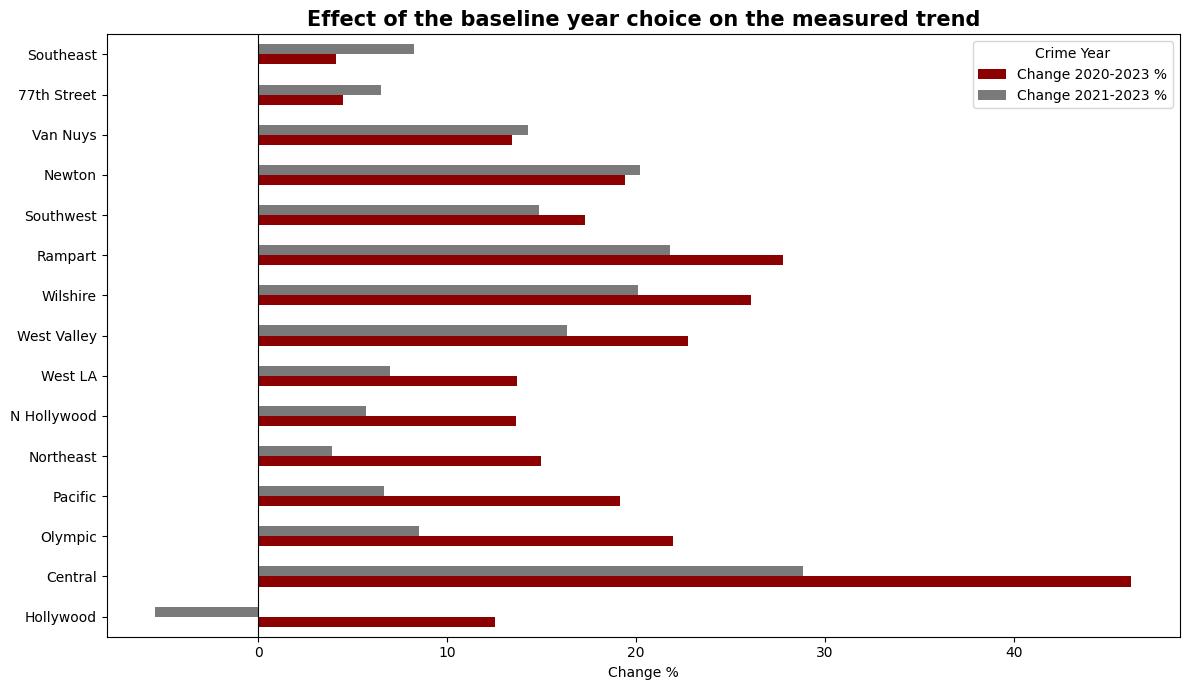

In [43]:
### 5.2 How much growth disappears after changing the baseline year?
compare = trend_A[['Change 2020-2023 %', 'Change 2021-2023 %']].copy()
compare['Difference (p.p.)'] = compare['Change 2020-2023 %'] - compare['Change 2021-2023 %']
compare = compare.sort_values('Difference (p.p.)', ascending=False)

print(f'Average pandemic-baseline effect: {compare['Difference (p.p.)'].mean():.1f} p.p.')

print(f'Area most sensitive to the choice of baseline: {compare.index[0]} '
      f'({compare.iloc[0]['Difference (p.p.)']:.1f} p.p.)')

ax = compare[['Change 2020-2023 %', 'Change 2021-2023 %']].plot(
    kind='barh', figsize=(12, 7), color=[dark_red, grey])
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Change %')
ax.set_ylabel('')
ax.set_title('Effect of the baseline year choice on the measured trend',
             fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

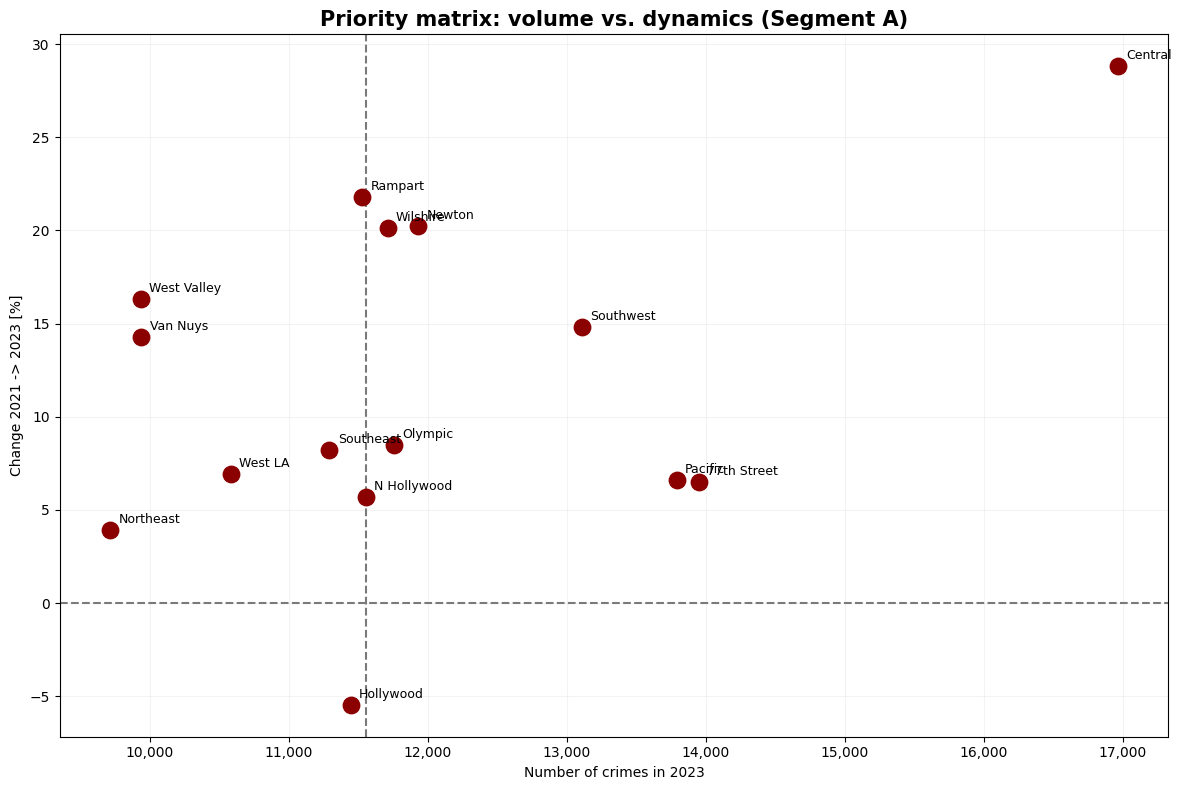

,Volume 2023,Change 2021-2023 %,Trend,Quadrant
Area,,,,
Central,16966,28.81,Increase,1. High volume / rising - priority
Newton,11933,20.22,Increase,1. High volume / rising - priority
Wilshire,11713,20.11,Increase,1. High volume / rising - priority
Southwest,13112,14.83,Increase,1. High volume / rising - priority
Olympic,11756,8.49,Increase,1. High volume / rising - priority
Pacific,13792,6.63,Increase,1. High volume / rising - priority
77th Street,13953,6.50,Ambiguous,1. High volume / rising - priority
N Hollywood,11557,5.72,Increase,1. High volume / rising - priority
Rampart,11529,21.81,Increase,3. Low volume / rising - early warning


In [44]:
### 5.3 Decision matrix: volume x trend
matrix = trend_A[[2023, 'Change 2021-2023 %', 'Trend']].copy()
matrix.columns = ['Volume 2023', 'Change 2021-2023 %', 'Trend']

vol_median = matrix['Volume 2023'].median()

def quadrant(r):
    """ Assigns a data point to one of four quadrants based on
    its volume (relative to the median) and the direction of change over time.
    """

    high = r['Volume 2023'] >= vol_median
    rising = r['Change 2021-2023 %'] > 0
    
    if high and rising:
        return '1. High volume / rising - priority'
    if high and not rising:
        return '2. High volume / not rising - maintain resources'
    if not high and rising:
        return '3. Low volume / rising - early warning'
    return '4. Low volume / not rising - monitoring'

matrix['Quadrant'] = matrix.apply(quadrant, axis=1)

fig, ax = plt.subplots(figsize=(12, 8))
ax.scatter(matrix['Volume 2023'], matrix['Change 2021-2023 %'],
           s=140, color=dark_red, zorder=3)
for area, r in matrix.iterrows():
    ax.annotate(area, (r['Volume 2023'], r['Change 2021-2023 %']),
                xytext=(6, 5), textcoords='offset points', fontsize=9)

ax.axvline(vol_median, linestyle='--', color=grey)
ax.axhline(0, linestyle='--', color=grey)
ax.set_xlabel('Number of crimes in 2023')
ax.set_ylabel('Change 2021 -> 2023 [%]')
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda v, p: f'{int(v):,}'))
ax.set_title('Priority matrix: volume vs. dynamics (Segment A)',
             fontsize=15, fontweight='bold')
ax.grid(alpha=0.15)
plt.tight_layout()
plt.show()

matrix.sort_values('Quadrant')

# Conclusion: 

The matrix shows a list of fifteen areas with four decision groups, each implying a different action: quadrant 1 needs a root-cause investigation, quadrant 2 needs maintained resourcing, quadrant 3 allows earlier, lower-cost intervention, quadrant 4 needs only monitoring.

Segment A splits into three of the four quadrants, no area falls into Quadrant 2 (high volume / not rising), which means **every high-volume area in this segment is still trending upward.**

**Quadrant 1:** High volume / rising (priority, 8 areas): Central, Newton, Wilshire, Southwest, Olympic, Pacific, 77th Street, N Hollywood. `Central` is the clearest case: the largest volume in the segment (16,966 in 2023) combined with the highest growth (+28.81% from 2021), and it also shows the single largest pandemic-baseline distortion (+17.4 p.p. for the the 2020 - 2023 figure of 46.21% overstates the real increase by well over half). 

All measures describe the number of reported crimes, not the number of events. Growth may partly reflect a higher propensity to report, or changes in registration practice.

# Part Six: What Is the Structure of Crime in the Priority Areas?

**Business questions 3 and 4:** which 5 crime types dominate each area, and which types recur across many areas?

A plain Top 5 table leads to a low-value conclusion ("vehicle theft dominates everywhere"), because it mostly reproduces the citywide structure. Alongside the share, a **specialization index (lift)** is therefore computed:
The specialization index lift is a measure that shows how much a given value deviates from a certain baseline.

$$\text{lift} = \frac{\text{share of type} \text{ in area}}{\text{share of type} \text{ citywide}}$$

Lift = 1.0 means the area's structure matches the citywide structure; lift = 2.0 means the crime type occurs twice as often as the city average would suggest. It is the lift, not the raw share, that reveals local specificity.

In [45]:
### 6.1 Top 5 + share + lift
city_share = df['Main Crime'].value_counts(normalize=True)

profile_A = (crime_A.groupby(['Area', 'Main Crime'])['Crime ID']
                    .count()
                    .reset_index(name='Crime Count'))

area_totals = profile_A.groupby('Area')['Crime Count'].transform('sum')

profile_A['Share in Area %'] = profile_A['Crime Count'] / area_totals * 100
profile_A['City Share %'] = profile_A['Main Crime'].map(city_share) * 100

profile_A['Lift'] = profile_A['Share in Area %'] / profile_A['City Share %']

profile_A['Rank'] = (profile_A.groupby('Area')['Crime Count']
                              .rank(method='first', ascending=False).astype(int))

top5_A = (profile_A[profile_A['Rank'] <= 5]
          .sort_values(['Area', 'Rank'])
          .reset_index(drop=True)
          [['Area', 'Rank', 'Main Crime', 'Crime Count',
            'Share in Area %', 'City Share %', 'Lift']])

# how much of an area's volume is covered by its Top 5 types
"""For each area, you are given the sum of the percentage shares of its top 5 types.
For example, if in the “Hollywood” area the top 5 crimes types have shares of
 20%, 15%, 10%, 8%, and 5%, the total will be 58%."""

top5_coverage = (top5_A.groupby('Area')['Share in Area %'].sum()
                       .sort_values(ascending=False)
                       .to_frame('Top 5 coverage in area %'))

print("Top 5 coverage of area volume:")
print(top5_coverage.to_string())

top5_A

Top 5 coverage of area volume:
             Top 5 coverage in area %
Area                                 
Southeast                       46.63
77th Street                     44.95
Central                         44.67
Newton                          44.60
West LA                         39.51
Rampart                         39.36
Olympic                         39.21
West Valley                     39.21
Van Nuys                        39.17
Pacific                         38.83
Southwest                       38.78
Northeast                       38.67
Hollywood                       38.07
N Hollywood                     38.05
Wilshire                        36.62


,Area,Rank,Main Crime,Crime Count,Share in Area %,City Share %,Lift
0,77th Street,1,VEHICLE - STOLEN,7221,13.13,10.68,1.23
1,77th Street,2,"ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT",5437,9.89,5.68,1.74
2,77th Street,3,BATTERY - SIMPLE ASSAULT,4283,7.79,7.91,0.98
3,77th Street,4,THEFT OF IDENTITY,4008,7.29,6.41,1.14
4,77th Street,5,INTIMATE PARTNER - SIMPLE ASSAULT,3763,6.84,4.98,1.37
...,...,...,...,...,...,...,...
70,Wilshire,1,BURGLARY,3445,8.22,6.09,1.35
71,Wilshire,2,VEHICLE - STOLEN,3405,8.12,10.68,0.76
72,Wilshire,3,BATTERY - SIMPLE ASSAULT,2967,7.08,7.91,0.89
73,Wilshire,4,BURGLARY FROM VEHICLE,2823,6.73,6.15,1.09


In [46]:
### 6.2 Area specialization - where structure deviates from the citywide pattern
MIN_COUNT = 300   # cutoff for rare categories, where lift is unstable

specialization = (profile_A[profile_A['Crime Count'] >= MIN_COUNT]
                  .sort_values('Lift', ascending=False)
                  .head(20)
                  [['Area', 'Main Crime', 'Crime Count', 'Share in Area %',
                    'City Share %', 'Lift']]
                  .reset_index(drop=True))

specialization

,Area,Main Crime,Crime Count,Share in Area %,City Share %,Lift
0,N Hollywood,CONTEMPT OF COURT,866,1.97,0.29,6.76
1,Pacific,"EMBEZZLEMENT, GRAND THEFT ($950.01 & OVER)",1201,2.34,0.41,5.65
2,Southwest,"VEHICLE, STOLEN - OTHER (MOTORIZED SCOOTERS, B...",558,1.14,0.21,5.29
3,Pacific,"VEHICLE, STOLEN - OTHER (MOTORIZED SCOOTERS, B...",568,1.11,0.21,5.15
4,77th Street,CONTEMPT OF COURT,701,1.27,0.29,4.36
5,Hollywood,PICKPOCKET,531,1.15,0.28,4.08
6,77th Street,SHOTS FIRED AT INHABITED DWELLING,335,0.61,0.18,3.46
7,Central,PICKPOCKET,557,0.94,0.28,3.33
8,Pacific,BIKE - STOLEN,1373,2.67,0.83,3.24
9,West LA,BIKE - STOLEN,1023,2.54,0.83,3.07


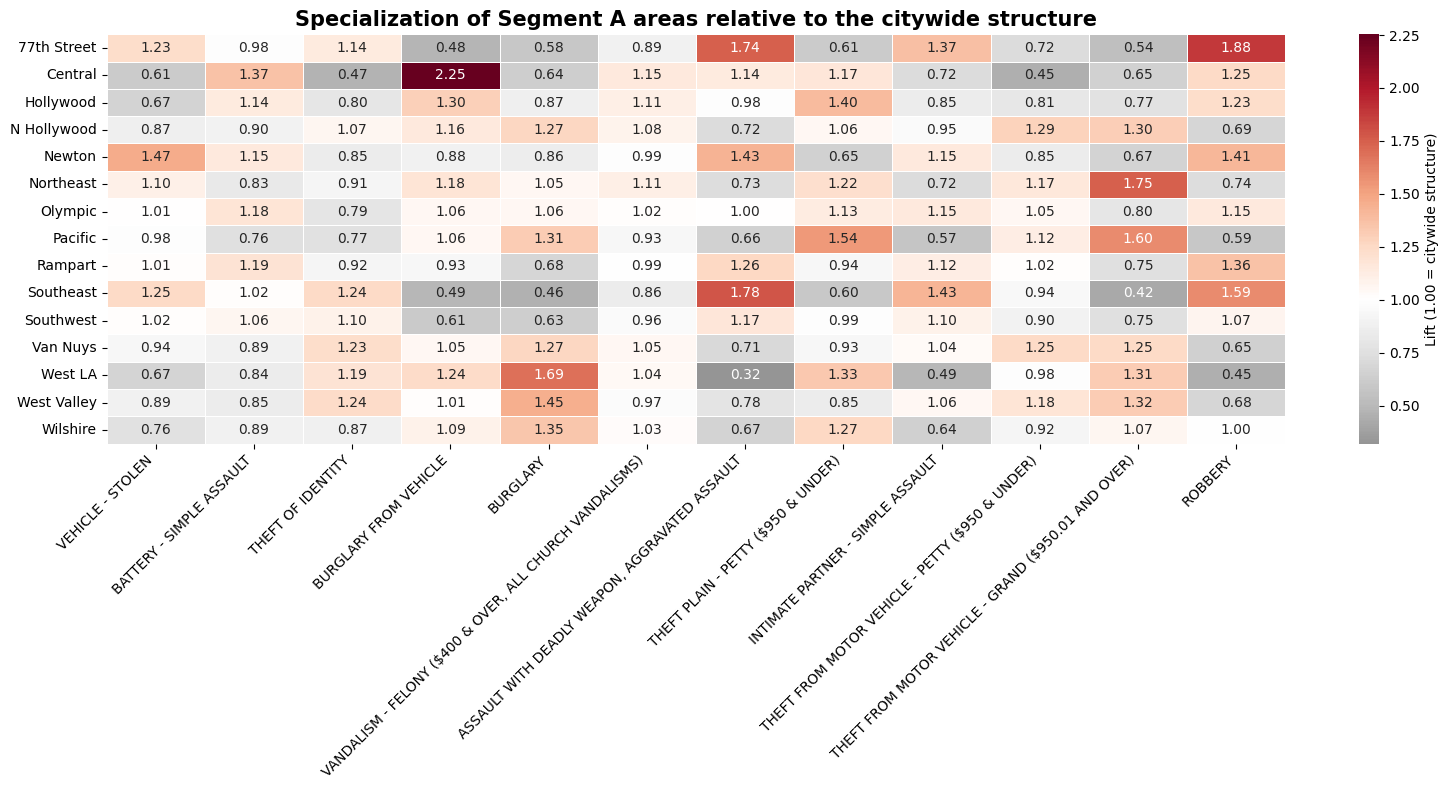

In [47]:
### 6.3 Lift heatmap: area x most common crime types
top_types = df['Main Crime'].value_counts().head(12).index.tolist()

heat = (profile_A[profile_A['Main Crime'].isin(top_types)]
        .pivot(index='Area', columns='Main Crime', values='Lift')
        .reindex(columns=top_types))

plt.figure(figsize=(16, 8))
sns.heatmap(heat, annot=True, fmt='.2f', center=1.0,
            cmap='RdGy_r', linewidths=0.5,
            cbar_kws={'label': 'Lift (1.00 = citywide structure)'})
plt.title('Specialization of Segment A areas relative to the citywide structure',
          fontsize=15, fontweight='bold')
plt.xlabel('')
plt.ylabel('')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [48]:
### 6.4 Crime types recurring across multiple areas
recurring = (top5_A.groupby('Main Crime')
                   .agg(**{
                       'Number of areas in Top 5': ('Area', 'nunique'),
                       'Average lift': ('Lift', 'mean'),
                       'Total volume': ('Crime Count', 'sum')
                   })
                   .sort_values(['Number of areas in Top 5', 'Total volume'],
                                ascending=False))

recurring['Share of Segment A areas %'] = recurring['Number of areas in Top 5'] / len(areas_A) * 100

# distinction: systemic problem (everywhere) vs local problem (few areas, high lift)
recurring['Type'] = np.where(
    recurring['Number of areas in Top 5'] >= len(areas_A) * 0.8,
    'Systemic (citywide)',
    'Local / mixed')

recurring

,Number of areas in Top 5,Average lift,Total volume,Share of Segment A areas %,Type
Main Crime,,,,,
VEHICLE - STOLEN,15,0.96,69111,100.00,Systemic (citywide)
BATTERY - SIMPLE ASSAULT,14,1.02,51370,93.33,Systemic (citywide)
BURGLARY FROM VEHICLE,10,1.24,34620,66.67,Local / mixed
BURGLARY,8,1.31,26477,53.33,Local / mixed
THEFT OF IDENTITY,8,1.14,25381,53.33,Local / mixed
"VANDALISM - FELONY ($400 & OVER, ALL CHURCH VANDALISMS)",7,1.05,20466,46.67,Local / mixed
"ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT",6,1.42,23548,40.00,Local / mixed
THEFT PLAIN - PETTY ($950 & UNDER),4,1.38,12817,26.67,Local / mixed
INTIMATE PARTNER - SIMPLE ASSAULT,3,1.32,9425,20.00,Local / mixed


# Conclusion:

Separating volume from lift makes it possible to distinguish **systemic problems** - crime types present in the Top 5 of nearly every area, with lift close to 1.0, which call for citywide action - from **local problems**, i.e. categories with high lift in individual areas, which justify a targeted intervention.

Top 5 coverage confirms these are broad-based crime areas, not single-issue ones. Top 5 types cover only 36–47% of each area's volume (Southeast highest at 46.63%, Wilshire lowest at 36.62%), meaning the majority of crime in every area comes from a long tail of lower-ranked categories.

Two crime types are systemic, not local, and this matters for where they should be managed. **VEHICLE - STOLEN** appears in the Top 5 of all 15 areas (avg. lift 0.96) and **BATTERY - SIMPLE ASSAULT** in 14 of 15 (avg. lift 1.02). Both have lift essentially at 1.0, confirming they are not area-specific problems, they dominate every Top 5 list simply because they dominate the city as a whole. These belong on a citywide policy track (vehicle security campaigns, assault de-escalation programs), not in an area-by-area intervention plan.

**Central** is the standout case: **BURGLARY FROM VEHICLE** makes up 13.87% of its crime mix at a lift of 2.25. The single most concentrated area–type combination in the segment, and visually the darkest cell on the heatmap. This alone justifies a targeted vehicle-burglary response specifically in Central, separate from any citywide vehicle-theft initiative.


**Limitation:** lift is based on `Main Crime`.

# Part Seven: Crimes Involving a Weapon

**Business question 3:** what is the proportion of crimes involving a weapon, and does it vary across areas?

**Comparability problem:** the raw share of reports with a filled-in `Weapon` field is not comparable across areas, because it depends on the crime mix. Assault almost always has a weapon field filled in, vehicle theft almost never does. An area with more crimes against persons will automatically show a higher rate, regardless of the actual level of weapon use.

The fix is **indirect standardization**: for each area, compute the expected share implied purely by its crime mix, then take the ratio of the observed value to the expected value.

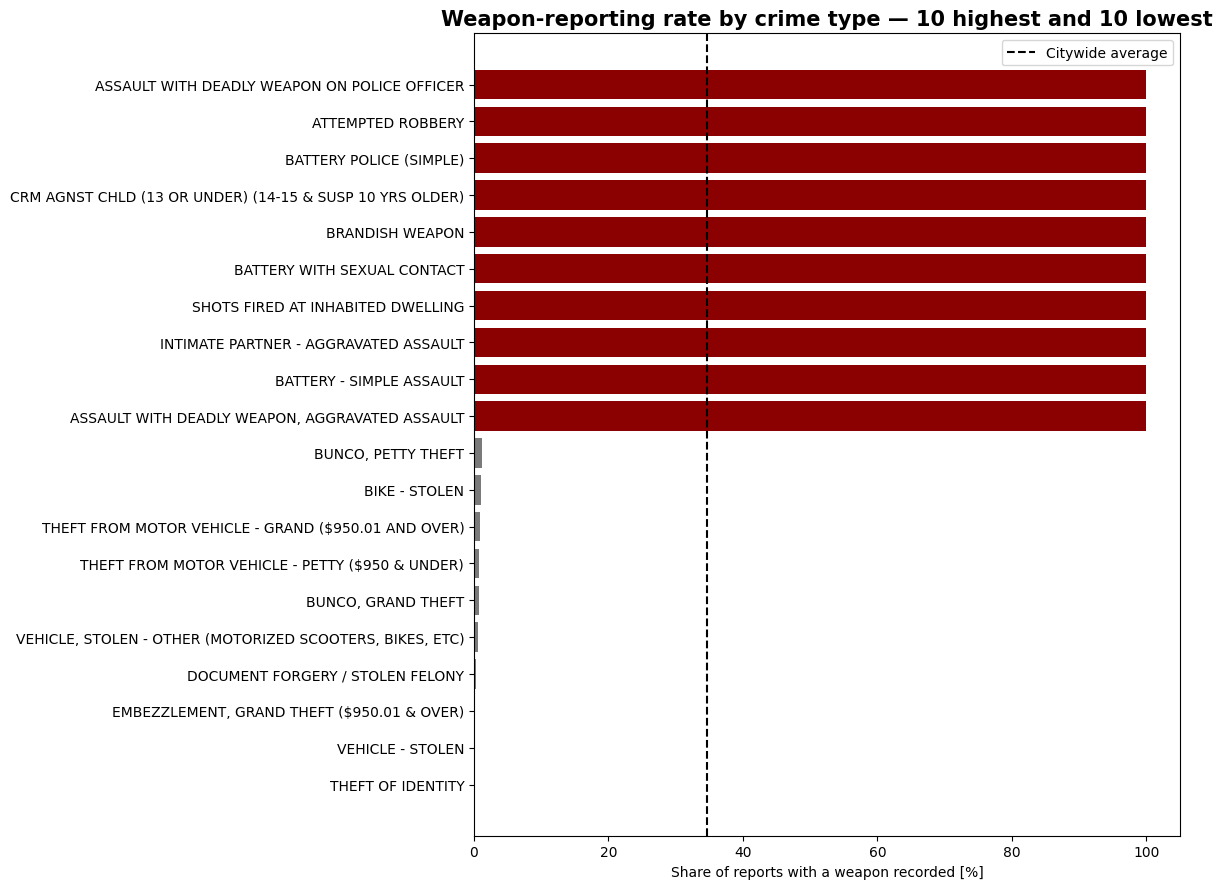

Range across all crime types (min 0.0 of the way to  max 100.0%): 100.0 p.p.


In [49]:
### 7 Weapon rate by Main Crime (citywide)
# Why standardization is needed — weapon rate varies enormously by crime type

weapon_by_type = (df.groupby('Main Crime')
                     .agg(Reports=('Crime ID', 'count'),
                          Weapon_pct=('Weapon Reported', lambda s: (s == 'Yes').mean() * 100))
                     .query('Reports >= 1000')  # drop rare categories, unstable rate
                     .sort_values('Weapon_pct', ascending=False))

top_bottom = pd.concat([weapon_by_type.head(10), weapon_by_type.tail(10)])

fig, ax = plt.subplots(figsize=(12, 9))
colors = [dark_red if v >= weapon_by_type['Weapon_pct'].median() else grey
          for v in top_bottom['Weapon_pct']]
ax.barh(top_bottom.index[::-1], top_bottom['Weapon_pct'][::-1], color=colors[::-1])
ax.axvline(df['Weapon Reported'].eq('Yes').mean() * 100, linestyle='--', color='black',
           label='Citywide average')
ax.set_xlabel('Share of reports with a weapon recorded [%]')
ax.set_title('Weapon-reporting rate by crime type — 10 highest and 10 lowest',
             fontsize=15, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

print(f'Range across all crime types (min {weapon_by_type['Weapon_pct'].min():.1f} of the way to  '
      f'max {weapon_by_type['Weapon_pct'].max():.1f}%): '
      f'{weapon_by_type['Weapon_pct'].max() - weapon_by_type['Weapon_pct'].min():.1f} p.p.')

Business context:
Areas differ in their MIX of crime types (more robberies vs more thefts), and weapon involvement naturally varies by crime type. 
Comparing raw "% of reports with a weapon" across areas is misleading, an area may look more dangerous just because it has more robbery-type crimes, not because
it's actually more armed for a given crime type.

This standardizes for that: we compute an "expected" weapon share per area based on national weapon rates per crime type and that area's crime mix,
then compare it to the "observed" (actual) share. The Observed/Expected ratio tells us whether an area has MORE weapon involvement than its crime
mix alone would predict (ratio > 1 = real signal, not just mix effect).

Finally, we compare raw vs standardized rankings to see how misleading the raw numbers would have been for prioritizing resources.

In [50]:
### 7.1 Raw vs standardized share

weapon_rate_by_type = df.groupby('Main Crime')['Weapon Reported'].apply(
    lambda s: (s == 'Yes').mean())

tmp = crime_A.copy()
tmp['weapon_flag'] = (tmp['Weapon Reported'] == 'Yes').astype(int)
tmp['expected_p'] = tmp['Main Crime'].map(weapon_rate_by_type)

weapon_std = (tmp.groupby('Area')
                 .agg(**{
                     'Reports': ('Crime ID', 'count'),
                     'With weapon': ('weapon_flag', 'sum'),
                     'Expected share %': ('expected_p', lambda s: s.mean() * 100)
                 }))

weapon_std['Observed share %'] = weapon_std['With weapon'] / weapon_std['Reports'] * 100
weapon_std['Observed/ Expected ratio'] = (weapon_std['Observed share %']
                           / weapon_std['Expected share %'])
weapon_std['Difference (p.p.)'] = (weapon_std['Observed share %']
                                   - weapon_std['Expected share %'])

weapon_std = weapon_std.sort_values('Observed/ Expected ratio', ascending=False)

# does the raw ranking differ from the standardized ranking?
weapon_std['Raw ranking'] = weapon_std['Observed share %'].rank(ascending=False).astype(int)
weapon_std['Observed/ Expected ranking'] = weapon_std['Observed/ Expected ratio'].rank(ascending=False).astype(int)
weapon_std['Rank shift'] = weapon_std['Raw ranking'] - weapon_std['Observed/ Expected ranking']

print(f"Average absolute rank shift after standardization: "
      f"{weapon_std['Rank shift'].abs().mean():.1f} positions")

weapon_std[['Reports', 'Observed share %', 'Expected share %',
            'Observed/ Expected ratio', 'Difference (p.p.)', 'Raw ranking',
            'Observed/ Expected ranking', 'Rank shift']]

Average absolute rank shift after standardization: 3.5 positions


,Reports,Observed share %,Expected share %,Observed/ Expected ratio,Difference (p.p.),Raw ranking,Observed/ Expected ranking,Rank shift
Area,,,,,,,,
Pacific,51351,27.53,24.35,1.13,3.17,11,1,10
Hollywood,46277,39.83,35.77,1.11,4.06,5,2,3
West LA,40313,23.78,22.06,1.08,1.73,15,3,12
Rampart,41223,41.54,40.40,1.03,1.14,4,4,0
Newton,43787,41.67,40.67,1.02,1.00,3,5,-2
Southeast,44325,47.90,46.96,1.02,0.94,2,6,-4
77th Street,54981,48.71,47.84,1.02,0.86,1,7,-6
Central,59456,39.31,38.67,1.02,0.64,6,8,-2
Southwest,49127,38.04,38.28,0.99,-0.23,7,9,-2


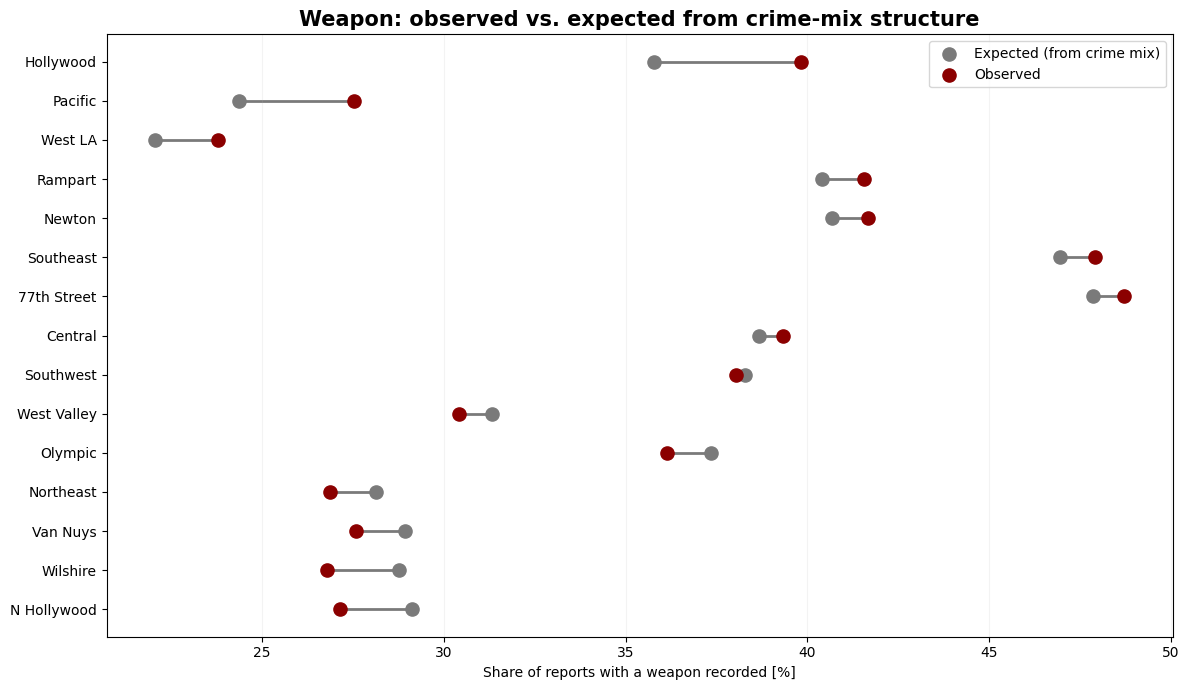

In [51]:
### 7.2 Visualization: observed vs expected
fig, ax = plt.subplots(figsize=(12, 7))
order = weapon_std.sort_values('Difference (p.p.)')
y = np.arange(len(order))

ax.hlines(y, order['Expected share %'], order['Observed share %'],
          color=grey, linewidth=2, zorder=1)
ax.scatter(order['Expected share %'], y, color=grey, s=90,
           label='Expected (from crime mix)', zorder=2)
ax.scatter(order['Observed share %'], y, color=dark_red, s=90,
           label='Observed', zorder=2)

ax.set_yticks(y)
ax.set_yticklabels(order.index)
ax.set_xlabel('Share of reports with a weapon recorded [%]')
ax.set_title('Weapon: observed vs. expected from crime-mix structure',
             fontsize=15, fontweight='bold')
ax.legend()
ax.grid(axis='x', alpha=0.15)
plt.tight_layout()
plt.show()

# Conclusion:

Standardization meaningfully reshuffles the ranking, the average absolute rank shift is 3.5 positions, confirming that the raw observed share was measuring each area's crime mix rather than a tendency toward weapon use.  **Pacific** jumps from 11th to 1st (+10 positions) and **West LA** moves from 15th to 3rd (+12 positions). Both areas whose raw ranking looked unremarkable but whose crime mix (fewer weapon-heavy categories like assault, more weapon-light categories) was suppressing their true rate.

**Critical limitation:** the `Weapon` field is empty in roughly 67% of records citywide. The indicator should be read as the **share of reports in which a weapon was recorded**, not as the actual share of crimes involving a weapon. If reporting completeness differs across areas, part of the indicator's variation is a registration artifact rather than a real phenomenon.

# Part Eight: Hypothesis Testing

**Hypothesis:** does the share of reports with a recorded weapon differ across Segment A areas?

- **H0:** the variables `Area` and `Weapon Reported` are independent,
- **H1:** the variables are not independent,
- significance level α = 0.05.

**Methodological note, without which the test is not useful:** with a sample size in the hundreds of thousands, a chi-square test will reject H0 for an arbitrarily small difference, the p-value is mostly measuring sample size here. Alongside the test, the following are therefore reported:

- **Cramér's V** — strength of association independent of sample size (0.1 = weak, 0.3 = moderate, 0.5 = strong),
- **range in percentage points** — the difference between the extreme areas, i.e. the effect size in units a business audience can interpret,
- **standardized residuals** — identification of the areas actually driving the rejection of H0 (|z| > 2).

## Why chi-square and Cramér's V?

**What we're testing:** whether two categorical variables: `Area` (15 categories) and `Weapon Reported` (Yes/No) are independent. This is the standard setup for the chi-square test of independence: it's built specifically for "does one categorical variable's distribution change across levels of another categorical variable," which is exactly the question here.

**Why Cramér's V specifically for the effect size:** it's the standard effect-size measure paired with chi-square when the contingency table is larger than 2×2 (here it's 15×2). It rescales the chi-square statistic to a 0–1 range that doesn't depend on sample size, which is exactly the gap the raw p-value leaves open at n = 672,620 — a statistic like odds ratio or Cohen's d isn't naturally defined for a 15-category variable, but Cramér's V is.

**Bottom line:** chi-square + Cramér's V is the standard pairing for this exact question (association between two categorical variables, effect size independent of sample size), and nothing in the data (small cell counts, need for control variables, continuous outcome) points toward a different test being more appropriate here. Logistic regression would be the natural next step if the project were extended to quantify each area's effect individually.

In [52]:
### 8.1 Chi-square test + effect size
chi_table = pd.crosstab(crime_A['Area'], crime_A['Weapon Reported'])
chi2, p_value, dof, expected = stats.chi2_contingency(chi_table)

n = chi_table.values.sum()
cramers_v = np.sqrt(chi2 / (n * (min(chi_table.shape) - 1)))

obs_share = chi_table['Yes'] / chi_table.sum(axis=1) * 100
range_pp = obs_share.max() - obs_share.min()

print(f"n                       = {n:,}")
print(f"Chi-square              = {chi2:,.1f}   (df = {dof})")
print(f"p-value                 = {p_value:.2e}")
print(f"Cramer's V               = {cramers_v:.4f}")
print(f"Weapon-share range       = {range_pp:.2f} p.p. "
      f"({obs_share.idxmin()}: {obs_share.min():.2f}% -> "
      f"{obs_share.idxmax()}: {obs_share.max():.2f}%)")
print()
print("Decision:", "reject H0" if p_value < 0.05 else "fail to reject H0",
      "at alpha = 0.05.")
print("Effect size interpretation:",
      'negligible' if cramers_v < 0.1 else
      'weak' if cramers_v < 0.3 else
      'moderate' if cramers_v < 0.5 else 'strong')

n                       = 672,620
Chi-square              = 18,701.5   (df = 14)
p-value                 = 0.00e+00
Cramer's V               = 0.1667
Weapon-share range       = 24.92 p.p. (West LA: 23.78% -> 77th Street: 48.71%)

Decision: reject H0 at alpha = 0.05.
Effect size interpretation: weak


In [53]:
### 8.2 Which areas drive the rejection of H0?
residuals = (chi_table - expected) / np.sqrt(expected)
residuals = residuals.round(2).sort_values('Yes', ascending=False)
residuals['Significant (|z| > 2)'] = np.where(residuals['Yes'].abs() > 2, 'yes', 'no')

residuals

Weapon Reported,No,Yes,Significant (|z| > 2)
Area,,,
77th Street,-38.74,52.29,yes
Southeast,-32.66,44.08,yes
Newton,-16.25,21.94,yes
Rampart,-15.44,20.85,yes
Central,-11.78,15.90,yes
Hollywood,-11.77,15.88,yes
Southwest,-7.20,9.72,yes
Olympic,-1.86,2.51,yes
West Valley,11.99,-16.18,yes


# Conclusion:
The area where the crime occurred is statistically linked to whether a weapon was reported in the police report.

With n = 672,620, the chi-square test rejects H0 (χ² = 18,701.5, df = 14, p < 0.001): Area and Weapon Reported are not independent. But as flagged before running the test, this result was expected almost regardless of the true effect size, given the sample size. The two numbers that actually carry information are Cramér's V and the range.

Cramér's V = 0.1667 classifies as a weak association. This is the headline finding of Part Eight: area membership explains only a small fraction of the variation in whether a weapon was reported. The statistical significance of the chi-square test should not be read as "area matters a lot for weapon involvement", it matters, but not by much, in relative terms.

# Part Nine: Forecast for the Following Year

**Business question 6:** what might the crime rate look like next year?

Last 8 months of the series vs. the earlier average (13,817):
  2023-05:  14,646  (106.0%)
  2023-06:  14,459  (104.6%)
  2023-07:  15,317  (110.9%)
  2023-08:  15,469  (112.0%)
  2023-09:  14,817  (107.2%)
  2023-10:  15,537  (112.4%)
  2023-11:  14,727  (106.6%)
  2023-12:  14,960  (108.3%)

Series truncated to 2023-11-01 — 47 monthly observations.


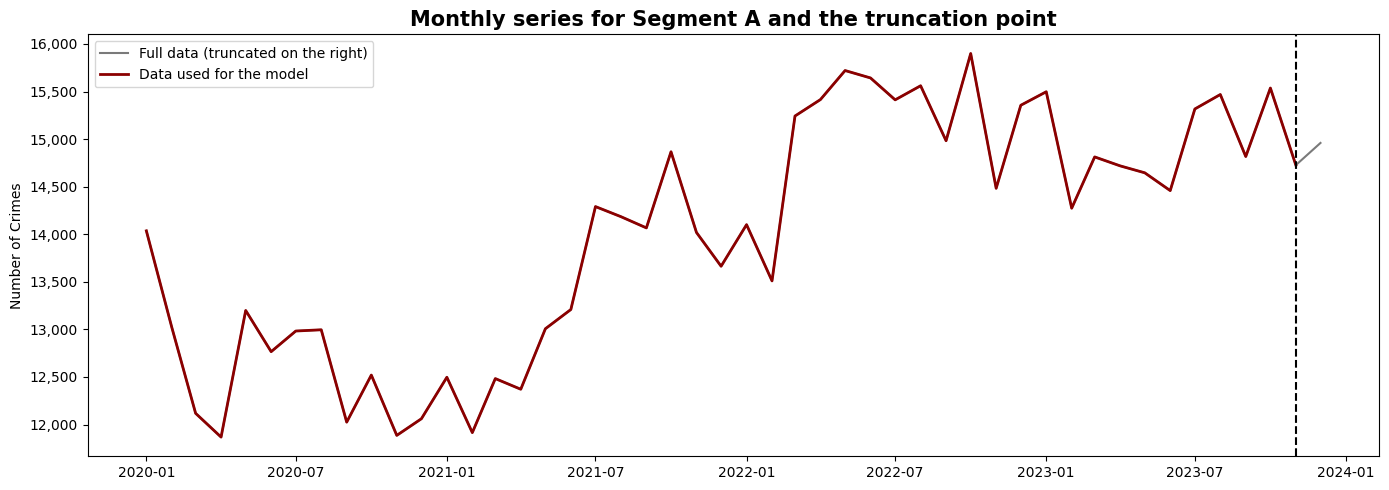

In [54]:
### 9.1 Diagnosing series truncation
monthly_total = (crime_A.set_index('Crime Date')
                        .resample('MS')['Crime ID']
                        .count())

tail = monthly_total.tail(8)
baseline = monthly_total.iloc[:-8].mean()

print("Last 8 months of the series vs. the earlier average "
      f"({baseline:,.0f}):")

for d, v in tail.items():
    flag = '  <-- suspiciously low' if v < baseline * 0.85 else ''
    print(f"  {d:%Y-%m}: {v:>7,}  ({v/baseline*100:5.1f}%){flag}")

# truncate to the last month with completeness >= 85% of the average
CUTOFF = '2023-11-01'
series = monthly_total.loc[:CUTOFF]
print(f"\nSeries truncated to {CUTOFF} — {len(series)} monthly observations.")

plt.figure(figsize=(14, 5))
plt.plot(monthly_total.index, monthly_total.values, color=grey,
         linewidth=1.5, label='Full data (truncated on the right)')
plt.plot(series.index, series.values, color=dark_red, linewidth=2,
         label='Data used for the model')
plt.axvline(pd.Timestamp(CUTOFF), linestyle='--', color='black')
plt.title('Monthly series for Segment A and the truncation point',
          fontsize=15, fontweight='bold')
plt.ylabel('Number of Crimes')
plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(lambda v, p: f'{int(v):,}'))
plt.legend()
plt.tight_layout()
plt.show()

VALIDATION (train 2020-2022, test 2023)
  MAPE, trend+seasonality model :   8.46%
  MAPE, seasonal-naive benchmark :   3.99%
  The model does NOT beat the benchmark.


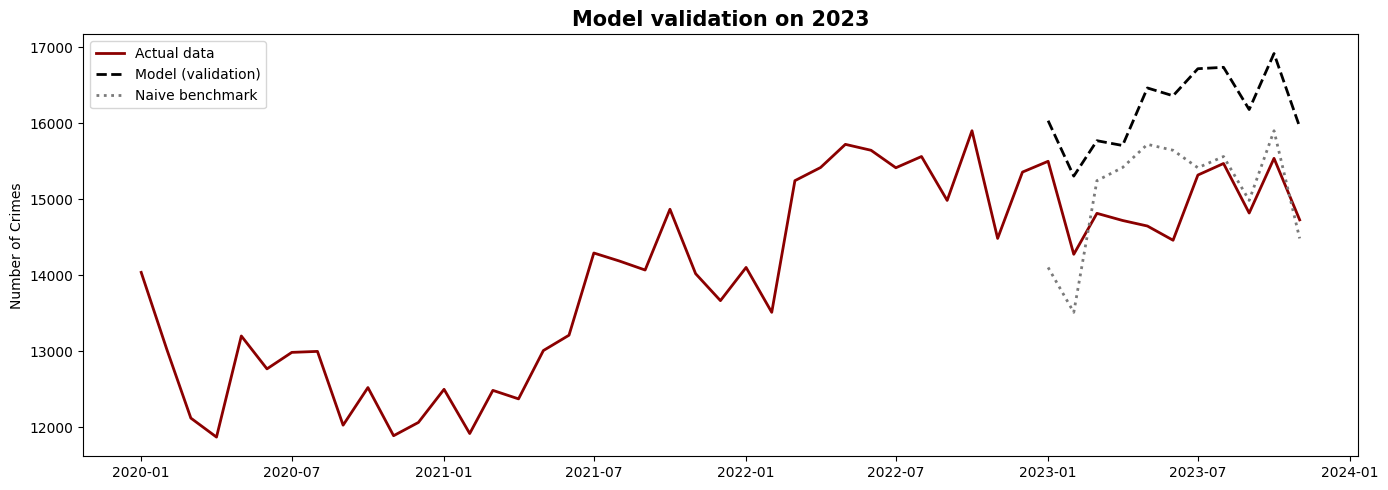

In [55]:
### 9.2 Model: trend + monthly seasonality
def make_features(index, t0):
    # Feature matrix: a time index plus 11 dummy variables for month-of-year.
    t = np.array([(d.year - t0.year) * 12 + (d.month - t0.month) for d in index])
    months = pd.get_dummies(pd.Series([d.month for d in index], index=index),
                            prefix='m', drop_first=True)
    months = months.reindex(columns=[f'm_{i}' for i in range(2, 13)], fill_value=0)
    return np.column_stack([t, months.values.astype(float)])


def mape(actual, pred):
    return float(np.mean(np.abs((actual - pred) / actual)) * 100)


t0 = series.index[0]

# --- validation: train on 2020-2022, test on 2023 ---
train = series.loc[:'2022-12-01']
test = series.loc['2023-01-01':]

model_val = LinearRegression().fit(make_features(train.index, t0), train.values)
pred_val = model_val.predict(make_features(test.index, t0))

# seasonal-naive benchmark: value from 12 months earlier
naive = series.shift(12).loc[test.index].values

print("VALIDATION (train 2020-2022, test 2023)")
print(f"  MAPE, trend+seasonality model : {mape(test.values, pred_val):6.2f}%")
print(f"  MAPE, seasonal-naive benchmark : {mape(test.values, naive):6.2f}%")
better = mape(test.values, pred_val) < mape(test.values, naive)
print(f"  The model {'beats' if better else 'does NOT beat'} the benchmark.")

plt.figure(figsize=(14, 5))
plt.plot(series.index, series.values, color=dark_red, linewidth=2, label='Actual data')
plt.plot(test.index, pred_val, linestyle='--', color='black', linewidth=2, label='Model (validation)')
plt.plot(test.index, naive, linestyle=':', color=grey, linewidth=2, label='Naive benchmark')
plt.title('Model validation on 2023', fontsize=15, fontweight='bold')
plt.ylabel('Number of Crimes')
plt.legend()
plt.tight_layout()
plt.show()

12-month forecast (Segment A): 193,774 crimes
Interval: 177,379 - 210,170 (+/- 8.5%, based on the validation error)


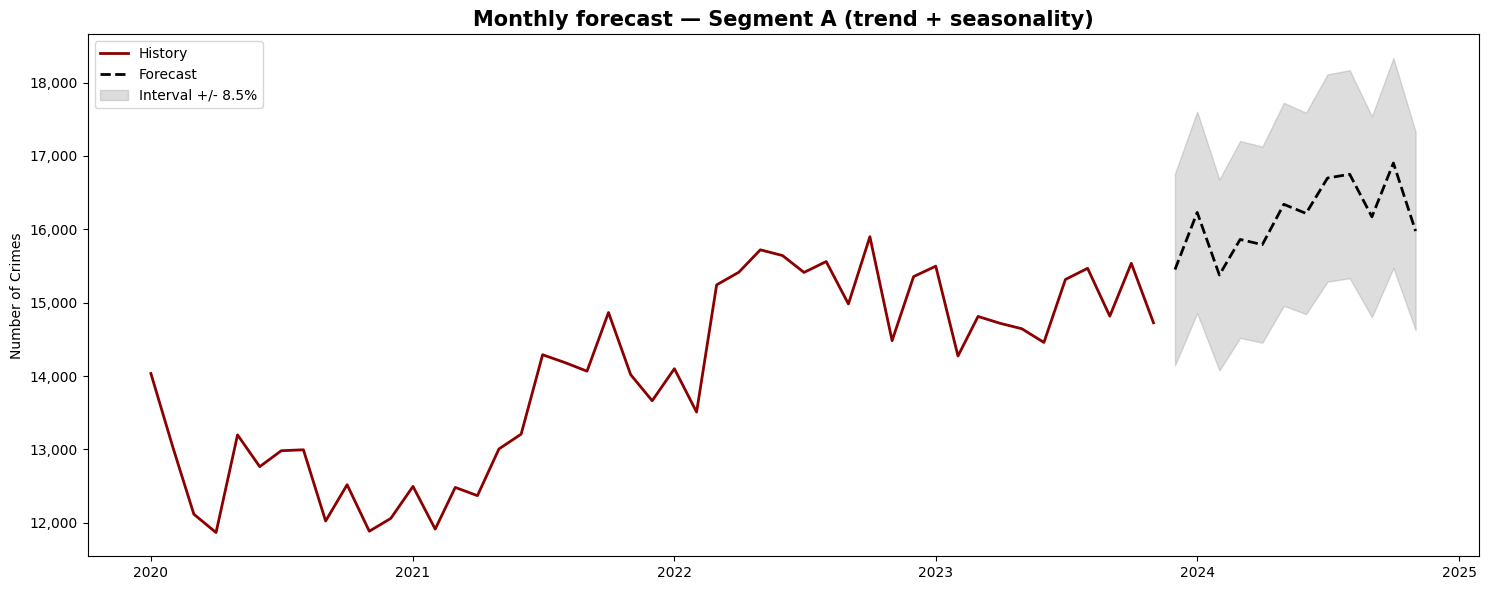

,Forecast,Lower bound,Upper bound
2023-12-01,"15,452.00","14,145.00","16,759.00"
2024-01-01,"16,231.00","14,858.00","17,604.00"
2024-02-01,"15,378.00","14,077.00","16,679.00"
2024-03-01,"15,862.00","14,520.00","17,204.00"
2024-04-01,"15,791.00","14,455.00","17,128.00"
2024-05-01,"16,341.00","14,959.00","17,724.00"
2024-06-01,"16,217.00","14,845.00","17,589.00"
2024-07-01,"16,699.00","15,286.00","18,112.00"
2024-08-01,"16,751.00","15,333.00","18,168.00"
2024-09-01,"16,171.00","14,803.00","17,539.00"


In [56]:
### 9.3 12-month forecast with an interval
model_final = LinearRegression().fit(make_features(series.index, t0), series.values)

future_index = pd.date_range(series.index[-1] + pd.offsets.MonthBegin(1),
                             periods=12, freq='MS')
forecast = np.maximum(model_final.predict(make_features(future_index, t0)), 0)

# interval based on the validation error (not on distributional assumptions)
err = mape(test.values, pred_val) / 100
lower, upper = forecast * (1 - err), forecast * (1 + err)

forecast_df = pd.DataFrame({
    'Forecast': forecast.round(0),
    'Lower bound': lower.round(0),
    'Upper bound': upper.round(0)
}, index=future_index)

print(f"12-month forecast (Segment A): {forecast.sum():,.0f} crimes")
print(f"Interval: {lower.sum():,.0f} - {upper.sum():,.0f} "
      f"(+/- {err*100:.1f}%, based on the validation error)")

plt.figure(figsize=(15, 6))
plt.plot(series.index, series.values, color=dark_red, linewidth=2, label='History')
plt.plot(future_index, forecast, linestyle='--', color='black', linewidth=2, label='Forecast')
plt.fill_between(future_index, lower, upper, color=grey, alpha=0.25,
                 label=f'Interval +/- {err*100:.1f}%')
plt.title('Monthly forecast — Segment A (trend + seasonality)',
          fontsize=15, fontweight='bold')
plt.ylabel('Number of Crimes')
plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(lambda v, p: f'{int(v):,}'))
plt.legend()
plt.tight_layout()
plt.show()

forecast_df

In [57]:
### 9.4 Forecast by area
rows = []
for area in areas_A:
    s = (crime_A[crime_A['Area'] == area]
         .set_index('Crime Date')
         .resample('MS')['Crime ID'].count()
         .reindex(series.index, fill_value=0))

    m = LinearRegression().fit(make_features(s.index, t0), s.values)
    f = np.maximum(m.predict(make_features(future_index, t0)), 0)

    rows.append({
        'Area': area,
        'History - monthly average': s.mean(),
        'Forecast - monthly average': f.mean(),
        'Forecast, 12 months': f.sum(),
        'Change vs. history %': (f.mean() - s.mean()) / s.mean() * 100
    })

forecast_A = (pd.DataFrame(rows)
              .sort_values('Forecast, 12 months', ascending=False)
              .reset_index(drop=True))

forecast_A

,Area,History - monthly average,Forecast - monthly average,"Forecast, 12 months",Change vs. history %
0,Central,"1,230.83","1,650.33","19,803.91",34.08
1,77th Street,"1,145.81","1,211.58","14,539.01",5.74
2,Pacific,"1,068.85","1,209.65","14,515.81",13.17
3,Southwest,"1,023.26","1,188.22","14,258.68",16.12
4,Olympic,921.19,"1,077.85","12,934.20",17.01
5,Newton,911.94,"1,071.68","12,860.11",17.52
6,Wilshire,869.85,"1,049.39","12,592.65",20.64
7,Rampart,856.96,"1,048.10","12,577.18",22.30
8,Hollywood,963.51,"1,046.42","12,557.10",8.61
9,N Hollywood,910.49,995.00,"11,939.98",9.28


# Part Ten: Final Conclusions and Recommendations

---

**1. LA crime does not follow the Pareto rule at the area level.**
Segment A spans 15 of 21 units (76% of reports). *Implication:* prioritizing at the area level does not narrow the problem. *Action:* move resource prioritization to the reporting-district level, keeping areas as the navigation level in the dashboard.

**2. The measured trend depends on the choice of baseline year, and it changes the story for several areas.**
Using 2020 as the base year overstates growth because the pandemic year is an unusually low starting point. On average this inflates the growth figure by about 7 percentage points, and for two areas it flips the conclusion entirely: Central looks less extreme once rebased (still the top priority, but not by as much), and Hollywood switches from "growing" to "declining."

**3. Two crime types are citywide problems, not area problems, the rest is where the real prioritization happens.**
Vehicle theft and simple assault appear in almost every area's Top 5, but at a lift near 1.0, meaning they're not more common in any one area than the citywide average, they just dominate everywhere. These belong on a citywide track, not an area-by-area one. The areas that actually stand out are Central (burglary from vehicle, more than double the expected rate) and the Southeast / 77th Street / Newton cluster (elevated aggravated assault and robbery). *Action:* give Central a dedicated vehicle-burglary response, treat the three violent-crime areas as one linked cluster, and handle vehicle theft/assault at the city level. *Needed to confirm:* time-of-day and exact-location data, to design the interventions.

**4. The raw weapon-use rate mostly reflects crime mix, not area behavior, and adjusting for it changes the priority list.**
Areas with more assault and robbery (77th Street, Southeast) naturally show a higher raw weapon-share, but that's explained by what crimes happen there, not by anything unusual about how they happen. After adjusting for crime mix, the areas that actually stand out are Pacific, Hollywood, and West LA, where weapons show up more often than their crime mix would predict. The hypothesis test confirms area does matter, but only weakly overall, the real signal is in the adjusted ranking, not the raw one.

**5. The forecast is a baseline scenario with limited durability.**
The model captures only trend and seasonality, and the series ends before the LAPD records-system migration in March 2024.

---